Adding 58 channels to all

Go task

In [1]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132 = pd.read_csv('/content/drive/MyDrive/combined_features_upto_sub132_21.csv')


In [3]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132.shape

(7250, 22)

In [4]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-133'  # Replace with your folder path


In [5]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-133_scans.tsv', 'meg']


In [6]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-133_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-133_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-133_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-133_coordsystem.json', 'sub-133_task-go_run-1_proc-tsss+mc_events.json', 'sub-133_task-noise_proc-tsss_channels.tsv', 'sub-133_task-noise_proc-tsss_meg.fif', 'sub-133_task-go_run-1_proc-tsss+mc_meg.json', 'sub-133_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-133_task-noise_proc-tsss_meg.json', 'sub-133_task-passive_run-1_proc-tsss+mc_events.json', 'sub-133_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-133_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-133_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-133_task-rest_run-1_proc-tsss+mc_events.json', 'sub-133_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-133_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-133_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-133_task-rest_run-1_proc-tsss+mc_meg.json']


In [7]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-133_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-133_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-133_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-133_task-rest_run-1_proc-tsss+mc_meg.fif']


In [8]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "go"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 50.6 MB/s eta 0:00:00
  Attempting uninstall: decorator
    Found existing installation: decorator 4.4.2
    Uninstalling decorator-4.4.2:
      Successfully uninstalled decorator-4.4.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.



Found .fif file: /content/drive/MyDrive/sub-133/meg/sub-133_task-go_run-1_proc-tsss+mc_meg.fif


In [9]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-133/meg/sub-133_task-go_run-1_proc-tsss+mc_meg.fif...
    Range : 173000 ... 1469999 =    173.000 ...  1469.999 secs
Ready.
Reading 0 ... 1296999  =      0.000 ...  1296.999 secs...
Finding events on: STI101
321 events found on stim channel STI101
Event IDs: [1 3 8]
Finding events on: STI101
321 events found on stim channel STI101
Event IDs: [1 3 8]
Resampling done
Filtering raw data in 3 contiguous segments
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fittin

Setting 2400 of 259400 (0.93%) samples to NaN, retaining 257000 (99.07%) samples.
Effective window size : 10.240 (s)


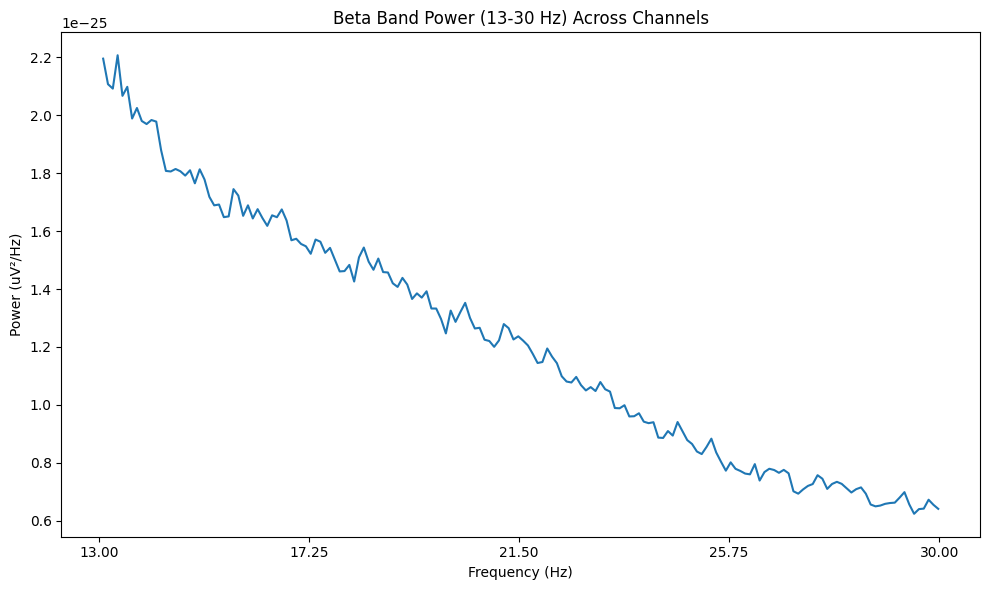

Extracted Beta Band Power (13-30 Hz) successfully.


In [10]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


In [11]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d133 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d133.head())
print(d133.shape)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 174.4/174.4 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 26.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 20.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.5/130.5 kB 4.1 MB/s eta 0:00:00
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.12

In [12]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d133_clean = d133.replace([np.inf, -np.inf], np.nan)
d133_clean = d133_clean.fillna(d133_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d133_scaled = pd.DataFrame(
    scaler.fit_transform(d133_clean),
    columns=d133_clean.columns,
    index=d133_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d133_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d133_scaled.index,
    columns=d133_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d133_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df133 = d133_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df133["Pd_indicator_meg"] = 0

print("\nShape of df5:", df133.shape)
print(df133.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [13]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132, df133], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.302044             0.058112          3.712576e-12  1.304284   
1       4.157456             0.060125          2.373146e-13  1.256616   
2       4.382286             0.057043          3.831662e-12  1.289192   
3       4.507192             0.055467          4.542028e-12  1.290808   
4       4.477668             0.055833          2.059621e-13  1.293730   
...          ...                  ...                   ...       ...   
7303    4.438705             0.056323          1.711625e-12  0.960171   
7304    4.609098             0.054235          1.898486e-12  0.982522   
7305    4.374711             0.057147  

In [14]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133.to_csv('/content/drive/MyDrive/combined_features_upto_go_sub00133_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133 preserved.")


RAM Used After Cleanup: 1.07 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133 preserved.


Sub-134

In [15]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-134'  # Replace with your folder path


In [16]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-134_scans.tsv', 'meg']


In [17]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-134_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-134_coordsystem.json', 'sub-134_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-134_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-134_task-go_run-1_proc-tsss+mc_events.json', 'sub-134_task-noise_proc-tsss_channels.tsv', 'sub-134_task-go_run-1_proc-tsss+mc_meg.json', 'sub-134_task-noise_proc-tsss_meg.fif', 'sub-134_task-noise_proc-tsss_meg.json', 'sub-134_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-134_task-passive_run-1_proc-tsss+mc_events.json', 'sub-134_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-134_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-134_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-134_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-134_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-134_task-rest_run-1_proc-tsss+mc_events.json', 'sub-134_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-134_task-rest_run-1_proc-tsss+mc_meg.json']


In [18]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-134_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-134_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-134_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-134_task-rest_run-1_proc-tsss+mc_meg.fif']


In [19]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "go"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-134/meg/sub-134_task-go_run-1_proc-tsss+mc_meg.fif


In [20]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-134/meg/sub-134_task-go_run-1_proc-tsss+mc_meg.fif...
    Range : 65000 ... 1293999 =     65.000 ...  1293.999 secs
Ready.
Reading 0 ... 1228999  =      0.000 ...  1228.999 secs...
Finding events on: STI101
323 events found on stim channel STI101
Event IDs: [1 3 8]
Finding events on: STI101
323 events found on stim channel STI101
Event IDs: [1 3 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting 

Effective window size : 10.240 (s)


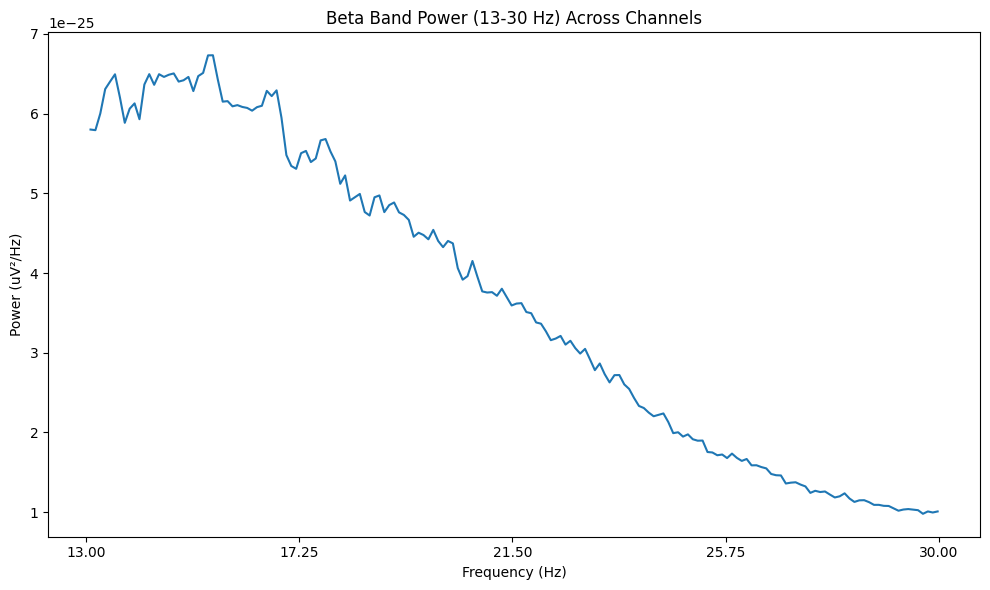

Extracted Beta Band Power (13-30 Hz) successfully.
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window 

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d134 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d134.head())
print(d134.shape)


In [22]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d134_clean = d134.replace([np.inf, -np.inf], np.nan)
d134_clean = d134_clean.fillna(d134_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d134_scaled = pd.DataFrame(
    scaler.fit_transform(d134_clean),
    columns=d134_clean.columns,
    index=d134_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d134_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d134_scaled.index,
    columns=d134_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d134_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df134 = d134_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df134["Pd_indicator_meg"] = 1

print("\nShape of df5:", df134.shape)
print(df134.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [23]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133, df134], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.302044             0.058112          3.712576e-12  1.304284   
1       4.157456             0.060125          2.373146e-13  1.256616   
2       4.382286             0.057043          3.831662e-12  1.289192   
3       4.507192             0.055467          4.542028e-12  1.290808   
4       4.477668             0.055833          2.059621e-13  1.293730   
...          ...                  ...                   ...       ...   
7361    3.939788             0.063443          3.409724e-12  0.799685   
7362    3.924329             0.063705          3.079115e-12  0.803031   
7363    4.071603             0.06140

In [24]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134.to_csv('/content/drive/MyDrive/final_7366_meg_go_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134 preserved.")


RAM Used After Cleanup: 1.07 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134 preserved.


In [25]:
combined_df85 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134

In [26]:
print(combined_df85.shape)
print(combined_df85.dtypes)
print(combined_df85.iloc[7350:7366])  # Selects rows 2 to 612 (inclusive)
print(combined_df85.shape)

(7366, 22)
burst_rate              float64
mean_burst_duration     float64
mean_burst_amplitude    float64
ibi_cv                  float64
duty_cycle              float64
peak_beta_freq          float64
burst_dur_cv            float64
burst_amp_cv            float64
mean_ibi                float64
env_mean                float64
env_var                 float64
env_skew                float64
env_kurt                float64
env_mod_rate            float64
abs_beta_power          float64
peak_beta_power         float64
beta_median_freq        float64
beta_bandwidth          float64
spectral_entropy        float64
spectral_flatness       float64
spectral_slope          float64
Pd_indicator_meg          int64
dtype: object
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
7350    3.406021             0.073399          7.350973e-12  0.907325   
7351    3.165175             0.078985          8.478633e-12  1.046947   
7352    3.493084             0.071570          3.434

In [27]:
print(combined_df85['Pd_indicator_meg'].value_counts())

Pd_indicator_meg
0    3770
1    3596
Name: count, dtype: int64


Identifying top 7 features through rf+shap

In [1]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd

previous_df = pd.read_csv('/content/drive/MyDrive/final_7366_meg_go_21.csv')

print("Loaded previous shape:", previous_df.shape)


Loaded previous shape: (7366, 22)


In [3]:
print(previous_df.head())

   burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0    4.302044             0.058112          3.712576e-12  1.304284   
1    4.157456             0.060125          2.373146e-13  1.256616   
2    4.382286             0.057043          3.831662e-12  1.289192   
3    4.507192             0.055467          4.542028e-12  1.290808   
4    4.477668             0.055833          2.059621e-13  1.293730   

   duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0    0.250000       13.476562      0.715342      0.302384  0.232480   
1    0.249966       13.378906      0.642147      0.340773  0.240482   
2    0.249977       20.703125      0.639045      0.297417  0.228140   
3    0.250000       21.875000      0.610992      0.262511  0.221829   
4    0.250000       22.558594      0.642656      0.244690  0.223365   

       env_mean  ...  env_kurt  env_mod_rate  abs_beta_power  peak_beta_power  \
0  1.984653e-12  ...  7.355256      0.195312    1.745991e-25     5.0139

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt

# -----------------------------
# Step 1: Separate Features & Target
# -----------------------------
X = previous_df.iloc[:, :-1]  # first 21 columns
y = previous_df.iloc[:, -1]   # Pd_indicator_meg

# -----------------------------
# Step 2: Ensure numeric
# -----------------------------
X = X.apply(pd.to_numeric, errors='coerce')
X.fillna(0, inplace=True)

# -----------------------------
# Step 3: Feature Scaling
# -----------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# -----------------------------
# Step 4: Train Random Forest
# -----------------------------
rf = RandomForestClassifier(
    n_estimators=500,
    random_state=42,
    class_weight='balanced'
)
rf.fit(X_scaled, y)

# -----------------------------
# Step 5: RF Feature Importance
# -----------------------------
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
}).sort_values(by="Importance", ascending=False)

# -----------------------------
# Step 6: SHAP Validation on Entire Dataset
# -----------------------------
X_subsample = X_scaled  # <-- use entire dataset now

explainer = shap.TreeExplainer(rf)
shap_values = explainer(X_subsample)

# Convert to array
shap_array = np.array(shap_values.values)

# --- SAFE: squeeze extra dimensions & ensure 2D ---
shap_array = np.atleast_2d(np.squeeze(shap_array))

# --- Handle binary classification ---
if shap_array.shape[1] != X.shape[1]:
    # Take last X.shape[1] columns if doubled
    shap_array = shap_array[:, -X.shape[1]:]

# --- Compute mean absolute SHAP per feature ---
shap_mean = np.mean(np.abs(shap_array), axis=0)

# --- Final safety: ensure 1D and exact match ---
shap_mean = np.ravel(shap_mean)
shap_mean = shap_mean[:X.shape[1]]  # guarantees it matches X.columns

# -----------------------------
# Step 7: Create SHAP importance DataFrame
# -----------------------------
shap_importance = pd.DataFrame({
    "Feature": X.columns,
    "SHAP_Importance": shap_mean
}).sort_values(by="SHAP_Importance", ascending=False)

# -----------------------------
# Step 8: Combine RF & SHAP Ranking
# -----------------------------
combined_importance = pd.merge(feature_importance, shap_importance, on="Feature")
combined_importance['RF_rank'] = combined_importance['Importance'].rank(ascending=False)
combined_importance['SHAP_rank'] = combined_importance['SHAP_Importance'].rank(ascending=False)
combined_importance['Avg_rank'] = (combined_importance['RF_rank'] + combined_importance['SHAP_rank']) / 2
combined_importance = combined_importance.sort_values(by="Avg_rank")

top7_features = combined_importance.head(7)
top7_names = top7_features['Feature'].tolist()

# -----------------------------
# Step 9: Create Top7 DataFrame
# -----------------------------
top7_df = previous_df[top7_names]
print("Top 7 features after RF + SHAP validation (SHAP on entire dataset):\n")
print(top7_df.head())
print(top7_df.shape)  # Should be (7366, 7)

Top 7 features after RF + SHAP validation (SHAP on entire dataset):

   env_kurt  env_skew  burst_amp_cv  burst_dur_cv    ibi_cv  env_mod_rate  \
0  7.355256  1.473360      0.302384      0.715342  1.304284      0.195312   
1  3.851293  1.449194      0.340773      0.642147  1.256616      0.976562   
2  2.973779  1.211840      0.297417      0.639045  1.289192      0.976562   
3  2.101304  0.995729      0.262511      0.610992  1.290808      0.976562   
4  1.237205  0.837088      0.244690      0.642656  1.293730      0.390625   

   burst_rate  
0    4.302044  
1    4.157456  
2    4.382286  
3    4.507192  
4    4.477668  
(7366, 7)


In [5]:
print(top7_df.shape)

(7366, 7)


In [6]:
print(top7_df.head)

<bound method NDFrame.head of       env_kurt  env_skew  burst_amp_cv  burst_dur_cv    ibi_cv  env_mod_rate  \
0     7.355256  1.473360      0.302384      0.715342  1.304284      0.195312   
1     3.851293  1.449194      0.340773      0.642147  1.256616      0.976562   
2     2.973779  1.211840      0.297417      0.639045  1.289192      0.976562   
3     2.101304  0.995729      0.262511      0.610992  1.290808      0.976562   
4     1.237205  0.837088      0.244690      0.642656  1.293730      0.390625   
...        ...       ...           ...           ...       ...           ...   
7361  1.166518  0.920639      0.251797      0.717606  0.799685      0.195312   
7362  1.057665  0.906381      0.250228      0.664948  0.803031      0.390625   
7363  0.974054  0.875395      0.243607      0.666422  0.783864      0.390625   
7364  1.327051  0.953954      0.256107      0.642381  0.776340      1.171875   
7365  1.135588  0.924406      0.249197      0.695583  0.770665      0.195312   

      bur

In [7]:
print(len(previous_df), len(top7_df))
print(len(previous_df.iloc[:, -1]))

7366 7366
7366


In [8]:
# Add last column to top7_df
final_df = top7_df.copy()
final_df['Pd_indicator_meg'] = previous_df.iloc[:, -1]

# Check shape
print(final_df.shape)  # Should be (7350, 8)

(7366, 8)


In [9]:
print(final_df.head)

<bound method NDFrame.head of       env_kurt  env_skew  burst_amp_cv  burst_dur_cv    ibi_cv  env_mod_rate  \
0     7.355256  1.473360      0.302384      0.715342  1.304284      0.195312   
1     3.851293  1.449194      0.340773      0.642147  1.256616      0.976562   
2     2.973779  1.211840      0.297417      0.639045  1.289192      0.976562   
3     2.101304  0.995729      0.262511      0.610992  1.290808      0.976562   
4     1.237205  0.837088      0.244690      0.642656  1.293730      0.390625   
...        ...       ...           ...           ...       ...           ...   
7361  1.166518  0.920639      0.251797      0.717606  0.799685      0.195312   
7362  1.057665  0.906381      0.250228      0.664948  0.803031      0.390625   
7363  0.974054  0.875395      0.243607      0.666422  0.783864      0.390625   
7364  1.327051  0.953954      0.256107      0.642381  0.776340      1.171875   
7365  1.135588  0.924406      0.249197      0.695583  0.770665      0.195312   

      bur

In [10]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
# Save top 7 features only
final_df.to_csv('/content/drive/MyDrive/top7_features_meg_go_7366_rf+shap.csv', index=False)

Sending meg and acoustic to mira-net and baseline models

MIRA-Net

In [1]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd

df_acoustic_top7 = pd.read_csv('/content/drive/MyDrive/final_acoustic_top7_rfc+shap_10-fold_analysis.csv')
print(df_acoustic_top7.shape)
print(df_acoustic_top7.head())

(7350, 8)
   Jitter:DDP  Standard deviation of periods     HNR  No. of pulses  \
0     0.01109                            0.0  21.033            0.0   
1     0.01394                            0.0  19.085            0.0   
2     0.01633                            0.0  20.651            0.0   
3     0.01505                            0.0  20.644            0.0   
4     0.01966                            0.0  19.649            0.0   

   No. of periods  Mean period  MDVP:PPQ  Status  
0             0.0          0.0   0.00554       1  
1             0.0          0.0   0.00696       1  
2             0.0          0.0   0.00781       1  
3             0.0          0.0   0.00698       1  
4             0.0          0.0   0.00908       1  


In [3]:
import pandas as pd

final_meg_df = pd.read_csv('/content/drive/MyDrive/top7_features_meg_go_7366_rf+shap.csv')

print("Loaded data shape:", final_meg_df.shape)

print(final_meg_df.head())

Loaded data shape: (7366, 8)
   env_kurt  env_skew  burst_amp_cv  burst_dur_cv    ibi_cv  env_mod_rate  \
0  7.355256  1.473360      0.302384      0.715342  1.304284      0.195312   
1  3.851293  1.449194      0.340773      0.642147  1.256616      0.976562   
2  2.973779  1.211840      0.297417      0.639045  1.289192      0.976562   
3  2.101304  0.995729      0.262511      0.610992  1.290808      0.976562   
4  1.237205  0.837088      0.244690      0.642656  1.293730      0.390625   

   burst_rate  Pd_indicator_meg  
0    4.302044                 0  
1    4.157456                 0  
2    4.382286                 0  
3    4.507192                 0  
4    4.477668                 0  


In [4]:
# ============================================================
#     SIMPLE + STABLE DANN + SCL + MLP CLASSIFIER
#     CROSS-MODAL + CROSS-PARTICIPANT ANALYSIS
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from torch.autograd import Function
import torch.nn.functional as F

import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ============================================================
# LOAD DATA
# ============================================================

# First 7 columns -> Features
# Last column     -> PD / HC labels

X_acoustic = df_acoustic_top7.iloc[:, :-1].values.astype(np.float32)
y_acoustic = df_acoustic_top7.iloc[:, -1].values.astype(np.int64)

X_meg = final_meg_df.iloc[:, :-1].values.astype(np.float32)
y_meg = final_meg_df.iloc[:, -1].values.astype(np.int64)

# ============================================================
# STANDARDIZATION
# ============================================================

scaler_acoustic = StandardScaler()
scaler_meg = StandardScaler()

X_acoustic = scaler_acoustic.fit_transform(X_acoustic)
X_meg = scaler_meg.fit_transform(X_meg)

# ============================================================
# DOMAIN LABELS
# ============================================================

# 0 -> Acoustic
# 1 -> MEG

domain_acoustic = np.zeros(len(X_acoustic))
domain_meg = np.ones(len(X_meg))

# ============================================================
# COMBINE
# ============================================================

X_all = np.vstack([
    X_acoustic,
    X_meg
]).astype(np.float32)

task_labels = np.hstack([
    y_acoustic,
    y_meg
]).astype(np.int64)

domain_labels = np.hstack([
    domain_acoustic,
    domain_meg
]).astype(np.int64)

# ============================================================
# TENSORS
# ============================================================

X_all_tensor = torch.tensor(
    X_all
).float().to(device)

task_labels_tensor = torch.tensor(
    task_labels
).long().to(device)

domain_labels_tensor = torch.tensor(
    domain_labels
).long().to(device)

# ============================================================
# GRADIENT REVERSAL
# ============================================================

class GradReverse(Function):

    @staticmethod
    def forward(ctx, x, lambd):

        ctx.lambd = lambd

        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad_output):

        return -ctx.lambd * grad_output, None

def grad_reverse(x, lambd):

    return GradReverse.apply(x, lambd)

# ============================================================
# SIMPLE RESIDUAL BLOCK
# ============================================================

class ResidualBlock(nn.Module):

    def __init__(self, dim):

        super().__init__()

        self.block = nn.Sequential(

            nn.Linear(dim, dim),
            nn.ReLU(),

            nn.Linear(dim, dim)
        )

    def forward(self, x):

        return F.relu(
            self.block(x) + x
        )

# ============================================================
# DANN + SCL MODEL
# ============================================================

class DANNContrastive(nn.Module):

    def __init__(self, input_dim, latent_dim=32):

        super().__init__()

        # ====================================================
        # SIMPLE ENCODER
        # ====================================================

        self.encoder = nn.Sequential(

            nn.Linear(input_dim, 128),
            nn.ReLU(),

            ResidualBlock(128),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Dropout(0.1),

            nn.Linear(64, latent_dim)
        )

        # ====================================================
        # TASK HEAD
        # ====================================================

        self.task_head = nn.Sequential(

            nn.Linear(latent_dim, 32),
            nn.ReLU(),

            nn.Dropout(0.2),

            nn.Linear(32, 2)
        )

        # ====================================================
        # DOMAIN HEAD
        # ====================================================

        self.domain_head = nn.Sequential(

            nn.Linear(latent_dim, 16),
            nn.ReLU(),

            nn.Linear(16, 2)
        )

    def forward(self, x, lambd=1.0):

        z = self.encoder(x)

        # L2 NORMALIZATION

        z_norm = F.normalize(
            z,
            p=2,
            dim=1
        )

        # DANN

        rev_z = grad_reverse(
            z_norm,
            lambd
        )

        task_out = self.task_head(z_norm)

        domain_out = self.domain_head(rev_z)

        return task_out, domain_out, z_norm

# ============================================================
# SUPERVISED CONTRASTIVE LOSS
# ============================================================

class SupConLoss(nn.Module):

    def __init__(self, temperature=0.07):

        super().__init__()

        self.temperature = temperature

    def forward(self, features, labels):

        device = features.device

        labels = labels.contiguous().view(-1, 1)

        mask = torch.eq(
            labels,
            labels.T
        ).float().to(device)

        similarity = torch.matmul(
            features,
            features.T
        ) / self.temperature

        logits_max, _ = torch.max(
            similarity,
            dim=1,
            keepdim=True
        )

        logits = similarity - logits_max.detach()

        logits_mask = torch.ones_like(mask) - torch.eye(
            mask.shape[0]
        ).to(device)

        mask = mask * logits_mask

        exp_logits = torch.exp(logits) * logits_mask

        log_prob = logits - torch.log(
            exp_logits.sum(1, keepdim=True) + 1e-8
        )

        mean_log_prob_pos = (
            mask * log_prob
        ).sum(1) / (mask.sum(1) + 1e-8)

        loss = -mean_log_prob_pos.mean()

        return loss

# ============================================================
# DATA LOADER
# ============================================================

dataset = TensorDataset(
    X_all_tensor,
    task_labels_tensor,
    domain_labels_tensor
)

loader = DataLoader(
    dataset,
    batch_size=128,
    shuffle=True
)

# ============================================================
# MODEL
# ============================================================

model = DANNContrastive(
    input_dim=X_all.shape[1],
    latent_dim=32
).to(device)

# ============================================================
# OPTIMIZER
# ============================================================

optimizer = optim.Adam(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

# ============================================================
# LOSSES
# ============================================================

task_loss_fn = nn.CrossEntropyLoss()

domain_loss_fn = nn.CrossEntropyLoss()

contrastive_loss_fn = SupConLoss(
    temperature=0.07
)

epochs = 120

print("\nTraining Started...\n")

# ============================================================
# TRAINING
# ============================================================

for epoch in range(epochs):

    model.train()

    total_correct = 0
    total_samples = 0

    # ========================================================
    # WEAKER DANN
    # ========================================================

    p = min(epoch / 50.0, 1.0)

    lambd = 0.25 * (
        2 / (1 + np.exp(-10 * p)) - 1
    )

    for xb, y_task, y_dom in loader:

        optimizer.zero_grad()

        task_out, dom_out, z = model(
            xb,
            lambd
        )

        # ====================================================
        # LOSSES
        # ====================================================

        loss_task = task_loss_fn(
            task_out,
            y_task
        )

        loss_domain = domain_loss_fn(
            dom_out,
            y_dom
        )

        loss_contrastive = contrastive_loss_fn(
            z,
            y_task
        )

        # ====================================================
        # FINAL LOSS
        # ====================================================

        loss = (
            3.0 * loss_task +
            0.25 * loss_domain +
            0.55 * loss_contrastive
        )

        loss.backward()

        optimizer.step()

        preds = task_out.argmax(1)

        total_correct += (
            preds == y_task
        ).sum().item()

        total_samples += len(y_task)

    acc = total_correct / total_samples

    print(
        f"Epoch {epoch+1}/{epochs} "
        f"| λ={lambd:.3f} "
        f"| Acc={acc:.4f}"
    )

# ============================================================
# EXTRACT LATENT FEATURES
# ============================================================

model.eval()

with torch.no_grad():

    fused_acoustic_32D = model(
        torch.tensor(X_acoustic).float().to(device),
        0
    )[2].cpu().numpy()

    fused_meg_32D = model(
        torch.tensor(X_meg).float().to(device),
        0
    )[2].cpu().numpy()

# ============================================================
# COMBINE LATENTS
# ============================================================

X_fused = np.vstack([
    fused_acoustic_32D,
    fused_meg_32D
])

y_fused = np.hstack([
    y_acoustic,
    y_meg
])

# ============================================================
# SIMPLE MLP CLASSIFIER
# ============================================================

class FinalMLP(nn.Module):

    def __init__(self, input_dim=32):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(input_dim, 64),
            nn.ReLU(),

            nn.Dropout(0.2),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 2)
        )

    def forward(self, x):

        return self.net(x)

# ============================================================
# CROSS PARTICIPANT EVALUATION
# ============================================================

print("\n======================================")
print(" CROSS PARTICIPANT ANALYSIS")
print("======================================\n")

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

accs = []
precs = []
recs = []
f1s = []
aucs = []

fold = 1

for train_idx, test_idx in skf.split(X_fused, y_fused):

    X_train = torch.tensor(
        X_fused[train_idx]
    ).float().to(device)

    X_test = torch.tensor(
        X_fused[test_idx]
    ).float().to(device)

    y_train = torch.tensor(
        y_fused[train_idx]
    ).long().to(device)

    y_test = y_fused[test_idx]

    clf = FinalMLP().to(device)

    optimizer_clf = optim.Adam(
        clf.parameters(),
        lr=1e-3
    )

    criterion = nn.CrossEntropyLoss()

    # ========================================================
    # TRAIN MLP
    # ========================================================

    clf.train()

    for epoch in range(80):

        optimizer_clf.zero_grad()

        outputs = clf(X_train)

        loss = criterion(
            outputs,
            y_train
        )

        loss.backward()

        optimizer_clf.step()

    # ========================================================
    # TEST
    # ========================================================

    clf.eval()

    with torch.no_grad():

        outputs = clf(X_test)

        probs = F.softmax(
            outputs,
            dim=1
        )[:, 1].cpu().numpy()

        preds = outputs.argmax(1).cpu().numpy()

    acc = accuracy_score(y_test, preds)

    prec = precision_score(y_test, preds)

    rec = recall_score(y_test, preds)

    f1 = f1_score(y_test, preds)

    auc = roc_auc_score(y_test, probs)

    accs.append(acc)
    precs.append(prec)
    recs.append(rec)
    f1s.append(f1)
    aucs.append(auc)

    print(f"Fold {fold}")

    print(f"Accuracy  : {acc:.4f}")
    print(f"Precision : {prec:.4f}")
    print(f"Recall    : {rec:.4f}")
    print(f"F1-Score  : {f1:.4f}")
    print(f"AUC       : {auc:.4f}")

    print()

    fold += 1

# ============================================================
# FINAL RESULTS
# ============================================================

print("\n======================================")
print(" FINAL RESULTS")
print("======================================\n")

print(f"Mean Accuracy  : {np.mean(accs)*100:.2f}%")
print(f"Mean Precision : {np.mean(precs)*100:.2f}%")
print(f"Mean Recall    : {np.mean(recs)*100:.2f}%")
print(f"Mean F1-Score  : {np.mean(f1s)*100:.2f}%")
print(f"Mean AUC       : {np.mean(aucs)*100:.2f}%")

print("\n======================================")
print(" LATENT SHAPES")
print("======================================\n")

print("Acoustic :", fused_acoustic_32D.shape)
print("MEG      :", fused_meg_32D.shape)


Training Started...

Epoch 1/120 | λ=0.000 | Acc=0.6797
Epoch 2/120 | λ=0.025 | Acc=0.7366
Epoch 3/120 | λ=0.049 | Acc=0.7749
Epoch 4/120 | λ=0.073 | Acc=0.7804
Epoch 5/120 | λ=0.095 | Acc=0.7862
Epoch 6/120 | λ=0.116 | Acc=0.7898
Epoch 7/120 | λ=0.134 | Acc=0.7905
Epoch 8/120 | λ=0.151 | Acc=0.7910
Epoch 9/120 | λ=0.166 | Acc=0.7889
Epoch 10/120 | λ=0.179 | Acc=0.7939
Epoch 11/120 | λ=0.190 | Acc=0.7963
Epoch 12/120 | λ=0.200 | Acc=0.7948
Epoch 13/120 | λ=0.208 | Acc=0.7963
Epoch 14/120 | λ=0.215 | Acc=0.7976
Epoch 15/120 | λ=0.221 | Acc=0.7972
Epoch 16/120 | λ=0.226 | Acc=0.7953
Epoch 17/120 | λ=0.230 | Acc=0.7987
Epoch 18/120 | λ=0.234 | Acc=0.7947
Epoch 19/120 | λ=0.237 | Acc=0.8020
Epoch 20/120 | λ=0.239 | Acc=0.8018
Epoch 21/120 | λ=0.241 | Acc=0.8044
Epoch 22/120 | λ=0.243 | Acc=0.8062
Epoch 23/120 | λ=0.244 | Acc=0.8031
Epoch 24/120 | λ=0.245 | Acc=0.8063
Epoch 25/120 | λ=0.246 | Acc=0.8091
Epoch 26/120 | λ=0.247 | Acc=0.8074
Epoch 27/120 | λ=0.247 | Acc=0.8061
Epoch 28/120 | 

In [5]:
import torch

# Assuming fused_acoustic_32D and fused_meg_32D are numpy arrays of shape (7350, 32)

# Step 1: Convert numpy arrays to torch tensors (float32)
fused_acoustic_tensor = torch.from_numpy(fused_acoustic_32D).float()
fused_meg_tensor = torch.from_numpy(fused_meg_32D).float()

# Step 2: Concatenate row-wise (along dim=0)
fused_output_tensor = torch.cat([fused_acoustic_tensor, fused_meg_tensor], dim=0)  # Shape: (14716, 32)

# Step 3: Print shape and dtype
print(fused_output_tensor.shape)  # torch.Size([14700, 32])
print(fused_output_tensor.dtype)  # torch.float32


torch.Size([14716, 32])
torch.float32


In [6]:
import torch
import numpy as np

# ------------------------
# Step 1: Extract targets correctly
# ------------------------

# Acoustic target from df_acoustic_top7 (last column)
y_acoustic = df_acoustic_top7.iloc[:, -1].values.astype(np.int32)   # (7350,)

# MEG target from final_meg_df (last column)
y_meg = final_meg_df.iloc[:, -1].values.astype(np.int32)           # (7350,)

# Convert to tensors (reshape to column)
acoustic_target_tensor = torch.tensor(y_acoustic).long().reshape(-1, 1)   # (7350, 1)
meg_target_tensor      = torch.tensor(y_meg).long().reshape(-1, 1)        # (7350, 1)

# ------------------------
# Step 2: Convert 32D latent features to tensors
# ------------------------

fused_acoustic_tensor = torch.from_numpy(fused_acoustic_32D).float()  # (7350, 32)
fused_meg_tensor      = torch.from_numpy(fused_meg_32D).float()       # (7350, 32)

# ------------------------
# Step 3: Attach target columns
# ------------------------

# Concatenate latent features with target
acoustic_full = torch.cat([fused_acoustic_tensor, acoustic_target_tensor.float()], dim=1)  # (7350, 65)
meg_full      = torch.cat([fused_meg_tensor,      meg_target_tensor.float()],      dim=1)  # (7350, 65)

# ------------------------
# Step 4: Concatenate both datasets
# ------------------------

fused_df = torch.cat([acoustic_full, meg_full], dim=0)  # (14700, 65)

# ------------------------
# Step 5: Separate features and labels for PyTorch
# ------------------------

X = fused_df[:, :-1].float()   # Features (32D) -> float32
y = fused_df[:, -1].long()     # Target -> int32

# ------------------------
# Step 6: Print shapes and dtypes
# ------------------------

print(f"Features shape: {X.shape}, dtype: {X.dtype}")  # (14700, 32), float32
print(f"Labels shape: {y.shape}, dtype: {y.dtype}")    # (14700,), int32

Features shape: torch.Size([14716, 32]), dtype: torch.float32
Labels shape: torch.Size([14716]), dtype: torch.int64


In [7]:
import torch
import pandas as pd

# fused_df shape = (14700, 33)

# Step 6: Convert fused tensor to numpy
fused_df_np = fused_df.numpy()

# Step 7: Create correct column names for 32 latent features + 1 label
feature_names = [f"feat_{i}" for i in range(32)]
feature_names.append("PD_Label_Combined")

# Step 8: Convert to DataFrame
fused_df_named = pd.DataFrame(fused_df_np, columns=feature_names)

# Step 9: Verify
print(fused_df_named.shape)
print(fused_df_named.head())
print(fused_df_named.tail())

(14716, 33)
     feat_0    feat_1    feat_2    feat_3    feat_4    feat_5    feat_6  \
0 -0.126427 -0.114952 -0.078690  0.099132 -0.339812 -0.071494  0.115922   
1 -0.124900 -0.112793 -0.080388  0.099141 -0.343459 -0.075806  0.109974   
2 -0.125655 -0.114467 -0.079171  0.099036 -0.340529 -0.072197  0.115108   
3 -0.125827 -0.114512 -0.079185  0.099072 -0.340561 -0.072261  0.115104   
4 -0.124713 -0.113317 -0.080163  0.098714 -0.343027 -0.074711  0.111026   

     feat_7    feat_8    feat_9  ...   feat_23   feat_24   feat_25   feat_26  \
0 -0.092660  0.355955 -0.061191  ... -0.226221 -0.015486 -0.265749  0.227756   
1 -0.088739  0.358757 -0.058565  ... -0.225790 -0.013341 -0.266038  0.224210   
2 -0.092121  0.356445 -0.060854  ... -0.225833 -0.015304 -0.265738  0.227484   
3 -0.092043  0.356314 -0.060832  ... -0.225893 -0.015234 -0.265762  0.227321   
4 -0.089320  0.358297 -0.059270  ... -0.226204 -0.013465 -0.265936  0.224793   

    feat_27   feat_28   feat_29   feat_30   feat_31  PD_

In [8]:
# Make a copy to be safe (optional)
fused_df_named_int = fused_df_named.copy()

# Convert only the last column to int
fused_df_named_int['PD_Label_Combined'] = fused_df_named_int['PD_Label_Combined'].astype(int)

# Verify
print(fused_df_named_int.dtypes)
print(fused_df_named_int.head())

feat_0               float32
feat_1               float32
feat_2               float32
feat_3               float32
feat_4               float32
feat_5               float32
feat_6               float32
feat_7               float32
feat_8               float32
feat_9               float32
feat_10              float32
feat_11              float32
feat_12              float32
feat_13              float32
feat_14              float32
feat_15              float32
feat_16              float32
feat_17              float32
feat_18              float32
feat_19              float32
feat_20              float32
feat_21              float32
feat_22              float32
feat_23              float32
feat_24              float32
feat_25              float32
feat_26              float32
feat_27              float32
feat_28              float32
feat_29              float32
feat_30              float32
feat_31              float32
PD_Label_Combined      int64
dtype: object
     feat_0    feat_1    feat

In [9]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
import pandas as pd

fused_df_named_int.to_csv('/content/drive//MyDrive/Sensor-level-fused_7366_fgo_MIRA-Net_data.csv', index=False)

In [1]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
fused_df_named_int = pd.read_csv('/content/drive//MyDrive/Sensor-level-fused_7366_fgo_MIRA-Net_data.csv')
fused_df_named_int.head()

,feat_0,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,feat_9,...,feat_23,feat_24,feat_25,feat_26,feat_27,feat_28,feat_29,feat_30,feat_31,PD_Label_Combined
0,-0.126427,-0.114952,-0.078690,0.099132,-0.339812,-0.071494,0.115922,-0.092660,0.355955,-0.061191,...,-0.226221,-0.015486,-0.265749,0.227756,-0.000887,0.069337,0.324372,-0.098287,-0.096886,1
1,-0.124900,-0.112793,-0.080388,0.099141,-0.343459,-0.075806,0.109974,-0.088739,0.358757,-0.058565,...,-0.225790,-0.013341,-0.266038,0.224210,0.003419,0.072588,0.326782,-0.093223,-0.097346,1
2,-0.125655,-0.114467,-0.079171,0.099036,-0.340529,-0.072197,0.115108,-0.092121,0.356446,-0.060854,...,-0.225833,-0.015304,-0.265738,0.227484,-0.000314,0.069948,0.324766,-0.097309,-0.096831,1
3,-0.125827,-0.114512,-0.079185,0.099072,-0.340561,-0.072261,0.115104,-0.092043,0.356314,-0.060832,...,-0.225893,-0.015234,-0.265762,0.227321,-0.000247,0.069940,0.324795,-0.097340,-0.096833,1
4,-0.124713,-0.113317,-0.080163,0.098714,-0.343027,-0.074711,0.111026,-0.089320,0.358297,-0.059270,...,-0.226204,-0.013465,-0.265936,0.224793,0.002331,0.072057,0.326590,-0.094288,-0.096789,1


In [4]:
# ============================================================
# ###8)###
# ENSEMBLE CLASSIFICATION WITH STRATIFIED 10-FOLD CV
# ============================================================

# ------------------ Install Required Packages ------------------

!pip install xgboost lightgbm catboost scikit-learn statsmodels matplotlib seaborn --quiet


# ------------------ Imports ------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.utils.class_weight import compute_class_weight

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold
)

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    confusion_matrix
)

from sklearn.ensemble import (
    VotingClassifier,
    StackingClassifier,
    RandomForestClassifier,
    HistGradientBoostingClassifier
)

from sklearn.linear_model import LogisticRegression

from xgboost import XGBClassifier

from statsmodels.stats.proportion import proportion_confint


# ============================================================
# STEP 1: PREPARE DATA
# ============================================================

X = fused_df_named_int[
    [f'feat_{i}' for i in range(32)]
].copy()

y = fused_df_named_int[
    "PD_Label_Combined"
].copy()


# ------------------ Convert X to numeric ------------------

X = X.apply(
    pd.to_numeric,
    errors='coerce'
)

X.fillna(
    0,
    inplace=True
)


# ============================================================
# STEP 2: CLASS WEIGHTS
# ============================================================

classes = np.unique(y)

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y
)

class_weights_dict = {
    int(classes[0]): float(class_weights[0]),
    int(classes[1]): float(class_weights[1])
}

print("\nClass Weights:")
print(class_weights_dict)


# ============================================================
# STEP 3: TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)


print("\nTrain Shape :", X_train.shape)
print("Test Shape  :", X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())


# ============================================================
# STEP 4: HANDLE CLASS IMBALANCE
# ============================================================

cw = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

cw_dict = dict(
    zip(
        np.unique(y_train),
        cw
    )
)

scale_pos_weight = (
    cw[1] / cw[0]
)

print("\nTraining Class Weights:")
print(cw_dict)

print(
    "\nXGBoost scale_pos_weight:",
    scale_pos_weight
)


# ============================================================
# STEP 5: BASE MODEL CREATION FUNCTION
# ============================================================

def create_models():

    # ---------------- XGBoost ----------------

    xgb = XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,

        scale_pos_weight=scale_pos_weight,

        eval_metric='logloss',

        random_state=42,
        n_jobs=-1
    )


    # ---------------- Random Forest ----------------

    rf = RandomForestClassifier(
        n_estimators=200,

        class_weight='balanced',

        random_state=42,
        n_jobs=-1
    )


    # ---------------- HistGradientBoosting ----------------

    hgb = HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=31,

        class_weight='balanced',

        random_state=42
    )


    return xgb, rf, hgb


# ============================================================
# STEP 6: STRATIFIED 10-FOLD CV
# ============================================================

skf = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)


# ============================================================
# STEP 7: EVALUATION FUNCTION
# ============================================================

def evaluate_model(model_name):

    # ========================================================
    # CV METRIC STORAGE
    # ========================================================

    cv_accuracy = []
    cv_precision = []
    cv_sensitivity = []
    cv_f1 = []
    cv_auc = []
    cv_balanced_accuracy = []


    # ========================================================
    # 10-FOLD STRATIFIED CROSS-VALIDATION
    # ========================================================

    for fold, (train_idx, val_idx) in enumerate(
        skf.split(X_train, y_train),
        start=1
    ):

        print(
            f"\n{model_name} | Fold {fold}/10"
        )


        # ----------------------------------------------------
        # Split fold
        # ----------------------------------------------------

        X_tr = X_train.iloc[
            train_idx
        ]

        X_val = X_train.iloc[
            val_idx
        ]

        y_tr = y_train.iloc[
            train_idx
        ]

        y_val = y_train.iloc[
            val_idx
        ]


        # ----------------------------------------------------
        # Scaling INSIDE EACH FOLD
        # ----------------------------------------------------

        scaler = StandardScaler()

        X_tr_scaled = scaler.fit_transform(
            X_tr
        )

        X_val_scaled = scaler.transform(
            X_val
        )


        # ----------------------------------------------------
        # Create FRESH models for every fold
        # ----------------------------------------------------

        xgb, rf, hgb = create_models()


        # ----------------------------------------------------
        # Select requested model
        # ----------------------------------------------------

        if model_name == "XGBoost":

            model = xgb


        elif model_name == "Random Forest":

            model = rf


        elif model_name == "HistGradientBoosting":

            model = hgb


        elif model_name == "Voting Fusion":

            model = VotingClassifier(
                estimators=[
                    ('xgb', xgb),
                    ('rf', rf),
                    ('hgb', hgb)
                ],
                voting='soft'
            )


        elif model_name == "Stacking Fusion":

            model = StackingClassifier(
                estimators=[
                    ('xgb', xgb),
                    ('rf', rf),
                    ('hgb', hgb)
                ],

                final_estimator=LogisticRegression(
                    max_iter=1000,
                    class_weight='balanced'
                ),

                passthrough=True,

                cv=5
            )


        else:

            raise ValueError(
                f"Unknown model: {model_name}"
            )


        # ----------------------------------------------------
        # Train fold
        # ----------------------------------------------------

        model.fit(
            X_tr_scaled,
            y_tr
        )


        # ----------------------------------------------------
        # Validation predictions
        # ----------------------------------------------------

        val_preds = model.predict(
            X_val_scaled
        )

        val_probs = model.predict_proba(
            X_val_scaled
        )[:, 1]


        # ----------------------------------------------------
        # Fold metrics
        # ----------------------------------------------------

        fold_accuracy = accuracy_score(
            y_val,
            val_preds
        )

        fold_precision = precision_score(
            y_val,
            val_preds,
            zero_division=0
        )

        fold_sensitivity = recall_score(
            y_val,
            val_preds,
            zero_division=0
        )

        fold_f1 = f1_score(
            y_val,
            val_preds,
            zero_division=0
        )

        fold_auc = roc_auc_score(
            y_val,
            val_probs
        )

        fold_balanced_accuracy = balanced_accuracy_score(
            y_val,
            val_preds
        )


        # ----------------------------------------------------
        # Store fold metrics
        # ----------------------------------------------------

        cv_accuracy.append(
            fold_accuracy
        )

        cv_precision.append(
            fold_precision
        )

        cv_sensitivity.append(
            fold_sensitivity
        )

        cv_f1.append(
            fold_f1
        )

        cv_auc.append(
            fold_auc
        )

        cv_balanced_accuracy.append(
            fold_balanced_accuracy
        )


        # ----------------------------------------------------
        # Print fold result
        # ----------------------------------------------------

        print(
            f"Accuracy            : {fold_accuracy:.4f}"
        )

        print(
            f"Precision           : {fold_precision:.4f}"
        )

        print(
            f"Sensitivity         : {fold_sensitivity:.4f}"
        )

        print(
            f"F1 Score            : {fold_f1:.4f}"
        )

        print(
            f"ROC-AUC             : {fold_auc:.4f}"
        )

        print(
            f"Balanced Accuracy   : "
            f"{fold_balanced_accuracy:.4f}"
        )


    # ========================================================
    # CV MEAN RESULTS
    # ========================================================

    cv_accuracy_mean = np.mean(
        cv_accuracy
    )

    cv_precision_mean = np.mean(
        cv_precision
    )

    cv_sensitivity_mean = np.mean(
        cv_sensitivity
    )

    cv_f1_mean = np.mean(
        cv_f1
    )

    cv_auc_mean = np.mean(
        cv_auc
    )

    cv_balanced_accuracy_mean = np.mean(
        cv_balanced_accuracy
    )


    # ========================================================
    # CROSS-VALIDATION RESULTS
    # ========================================================

    print(
        "\n================================================"
    )

    print(
        f"{model_name} - Cross-Validation (10-fold)"
    )

    print(
        "================================================"
    )

    print(
        f"Accuracy            : "
        f"{cv_accuracy_mean:.4f}"
    )

    print(
        f"Precision           : "
        f"{cv_precision_mean:.4f}"
    )

    print(
        f"Recall/Sensitivity  : "
        f"{cv_sensitivity_mean:.4f}"
    )

    print(
        f"F1 Score            : "
        f"{cv_f1_mean:.4f}"
    )

    print(
        f"ROC-AUC             : "
        f"{cv_auc_mean:.4f}"
    )

    print(
        f"Balanced Accuracy   : "
        f"{cv_balanced_accuracy_mean:.4f}"
    )


    # ========================================================
    # TRAIN FINAL MODEL ON COMPLETE TRAINING SET
    # ========================================================

    final_scaler = StandardScaler()

    X_train_final_scaled = final_scaler.fit_transform(
        X_train
    )

    X_test_final_scaled = final_scaler.transform(
        X_test
    )


    # --------------------------------------------------------
    # Create fresh final models
    # --------------------------------------------------------

    xgb, rf, hgb = create_models()


    if model_name == "XGBoost":

        final_model = xgb


    elif model_name == "Random Forest":

        final_model = rf


    elif model_name == "HistGradientBoosting":

        final_model = hgb


    elif model_name == "Voting Fusion":

        final_model = VotingClassifier(
            estimators=[
                ('xgb', xgb),
                ('rf', rf),
                ('hgb', hgb)
            ],
            voting='soft'
        )


    elif model_name == "Stacking Fusion":

        final_model = StackingClassifier(
            estimators=[
                ('xgb', xgb),
                ('rf', rf),
                ('hgb', hgb)
            ],

            final_estimator=LogisticRegression(
                max_iter=1000,
                class_weight='balanced'
            ),

            passthrough=True,

            cv=5
        )


    # ========================================================
    # FINAL TRAINING
    # ========================================================

    final_model.fit(
        X_train_final_scaled,
        y_train
    )


    # ========================================================
    # TEST PREDICTIONS
    # ========================================================

    test_preds = final_model.predict(
        X_test_final_scaled
    )

    test_probs = final_model.predict_proba(
        X_test_final_scaled
    )[:, 1]


    # ========================================================
    # TEST METRICS
    # ========================================================

    accuracy = accuracy_score(
        y_test,
        test_preds
    )

    precision = precision_score(
        y_test,
        test_preds,
        zero_division=0
    )

    sensitivity = recall_score(
        y_test,
        test_preds,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        test_preds,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_test,
        test_probs
    )

    balanced_accuracy = balanced_accuracy_score(
        y_test,
        test_preds
    )

    mcc = matthews_corrcoef(
        y_test,
        test_preds
    )


    # ========================================================
    # CONFUSION MATRIX
    # ========================================================

    cm = confusion_matrix(
        y_test,
        test_preds,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()


    # ========================================================
    # SENSITIVITY / SPECIFICITY
    # ========================================================

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )


    # ========================================================
    # 95% CONFIDENCE INTERVALS
    # ========================================================

    # ---------------- Accuracy CI ----------------

    acc_low, acc_high = proportion_confint(
        count=int(round(accuracy * len(y_test))),
        nobs=len(y_test),
        alpha=0.05,
        method='wilson'
    )


    # ---------------- Precision CI ----------------

    precision_low, precision_high = proportion_confint(
        count=tp,
        nobs=(tp + fp),
        alpha=0.05,
        method='wilson'
    ) if (tp + fp) > 0 else (0.0, 0.0)


    # ---------------- Sensitivity CI ----------------

    sensitivity_low, sensitivity_high = proportion_confint(
        count=tp,
        nobs=(tp + fn),
        alpha=0.05,
        method='wilson'
    ) if (tp + fn) > 0 else (0.0, 0.0)


    # ---------------- Specificity CI ----------------

    specificity_low, specificity_high = proportion_confint(
        count=tn,
        nobs=(tn + fp),
        alpha=0.05,
        method='wilson'
    ) if (tn + fp) > 0 else (0.0, 0.0)


    # ========================================================
    # TEST SET PERFORMANCE
    # ========================================================

    print(
        "\n================================================"
    )

    print(
        f"{model_name} - Test Set Performance"
    )

    print(
        "================================================"
    )

    print(
        f"Accuracy            : {accuracy:.4f} "
        f"(95% CI: "
        f"{acc_low:.4f}-{acc_high:.4f})"
    )

    print(
        f"Precision           : {precision:.4f} "
        f"(95% CI: "
        f"{precision_low:.4f}-{precision_high:.4f})"
    )

    print(
        f"Sensitivity         : {sensitivity:.4f} "
        f"(95% CI: "
        f"{sensitivity_low:.4f}-{sensitivity_high:.4f})"
    )

    print(
        f"Specificity         : {specificity:.4f} "
        f"(95% CI: "
        f"{specificity_low:.4f}-{specificity_high:.4f})"
    )

    print(
        f"F1 Score            : {f1:.4f}"
    )

    print(
        f"ROC-AUC             : {roc_auc:.4f}"
    )

    print(
        f"Balanced Accuracy   : "
        f"{balanced_accuracy:.4f}"
    )

    print(
        f"MCC                 : {mcc:.4f}"
    )


    # ========================================================
    # CONFUSION MATRIX
    # ========================================================

    print(
        "\nConfusion Matrix:"
    )

    print(cm)

    print(
        "\nTN :", tn
    )

    print(
        "FP :", fp
    )

    print(
        "FN :", fn
    )

    print(
        "TP :", tp
    )


    # ========================================================
    # STORE RESULTS
    # ========================================================

    result = {

        # ---------------- CV ----------------

        "CV Accuracy":
            cv_accuracy_mean,

        "CV Precision":
            cv_precision_mean,

        "CV Sensitivity":
            cv_sensitivity_mean,

        "CV F1":
            cv_f1_mean,

        "CV ROC-AUC":
            cv_auc_mean,

        "CV Balanced Accuracy":
            cv_balanced_accuracy_mean,


        # ---------------- Test ----------------

        "Accuracy":
            accuracy,

        "Accuracy CI Low":
            acc_low,

        "Accuracy CI High":
            acc_high,


        "Precision":
            precision,

        "Precision CI Low":
            precision_low,

        "Precision CI High":
            precision_high,


        "Sensitivity":
            sensitivity,

        "Sensitivity CI Low":
            sensitivity_low,

        "Sensitivity CI High":
            sensitivity_high,


        "Specificity":
            specificity,

        "Specificity CI Low":
            specificity_low,

        "Specificity CI High":
            specificity_high,


        "F1":
            f1,

        "ROC-AUC":
            roc_auc,

        "Balanced Accuracy":
            balanced_accuracy,

        "MCC":
            mcc,


        # ---------------- Confusion Matrix ----------------

        "TN":
            tn,

        "FP":
            fp,

        "FN":
            fn,

        "TP":
            tp
    }


    return result


# ============================================================
# STEP 8: EVALUATE ALL MODELS
# ============================================================

model_names = [
    "XGBoost",
    "Random Forest",
    "HistGradientBoosting",
    "Voting Fusion",
    "Stacking Fusion"
]


results = {}

for name in model_names:

    print(
        "\n\n################################################"
    )

    print(
        f"Evaluating: {name}"
    )

    print(
        "################################################"
    )

    results[name] = evaluate_model(
        name
    )


# ============================================================
# STEP 9: FINAL RESULTS DATAFRAME
# ============================================================

results_df = pd.DataFrame(
    results
).T


# ============================================================
# STEP 10: ORDER RESULTS
# ============================================================

results_df = results_df[
    [

        # ---------------- CV ----------------

        "CV Accuracy",
        "CV Precision",
        "CV Sensitivity",
        "CV F1",
        "CV ROC-AUC",
        "CV Balanced Accuracy",


        # ---------------- Test ----------------

        "Accuracy",
        "Accuracy CI Low",
        "Accuracy CI High",

        "Precision",
        "Precision CI Low",
        "Precision CI High",

        "Sensitivity",
        "Sensitivity CI Low",
        "Sensitivity CI High",

        "Specificity",
        "Specificity CI Low",
        "Specificity CI High",

        "F1",
        "ROC-AUC",
        "Balanced Accuracy",
        "MCC",

        # ---------------- Confusion Matrix ----------------

        "TN",
        "FP",
        "FN",
        "TP"
    ]
]


# ============================================================
# STEP 11: DISPLAY FINAL RESULTS
# ============================================================

print(
    "\n================================================"
)

print(
    "FINAL MODEL COMPARISON"
)

print(
    "================================================\n"
)


display(
    results_df.sort_values(
        by="F1",
        ascending=False
    )
)


Class Weights:
{0: 1.6505159264244056, 1: 0.717293819457984}

Train Shape : (11772, 32)
Test Shape  : (2944, 32)

Training Class Distribution:
PD_Label_Combined
1    8206
0    3566
Name: count, dtype: int64

Testing Class Distribution:
PD_Label_Combined
1    2052
0     892
Name: count, dtype: int64

Training Class Weights:
{np.int64(0): np.float64(1.6505888951205834), np.int64(1): np.float64(0.7172800389958567)}

XGBoost scale_pos_weight: 0.43456007799171337


################################################
Evaluating: XGBoost
################################################

XGBoost | Fold 1/10
Accuracy            : 0.8616
Precision           : 0.9727
Sensitivity         : 0.8246
F1 Score            : 0.8926
ROC-AUC             : 0.9580
Balanced Accuracy   : 0.8857

XGBoost | Fold 2/10
Accuracy            : 0.8506
Precision           : 0.9627
Sensitivity         : 0.8173
F1 Score            : 0.8841
ROC-AUC             : 0.9384
Balanced Accuracy   : 0.8722

XGBoost | Fold 3/10
Accur

,CV Accuracy,CV Precision,CV Sensitivity,CV F1,CV ROC-AUC,CV Balanced Accuracy,Accuracy,Accuracy CI Low,Accuracy CI High,Precision,...,Specificity CI Low,Specificity CI High,F1,ROC-AUC,Balanced Accuracy,MCC,TN,FP,FN,TP
Random Forest,0.855333,0.896659,0.895806,0.896192,0.933020,0.829002,0.847826,0.834398,0.860347,0.882634,...,0.693973,0.752535,0.891996,0.930489,0.812887,0.635032,646.0,246.0,202.0,1850.0
Voting Fusion,0.854823,0.947279,0.838409,0.889483,0.940395,0.865505,0.851902,0.838613,0.864274,0.940087,...,0.853475,0.896658,0.887860,0.936745,0.858906,0.680888,782.0,110.0,326.0,1726.0
HistGradientBoosting,0.848793,0.960314,0.816840,0.882743,0.940755,0.869585,0.846467,0.832994,0.859037,0.948430,...,0.875170,0.915148,0.882169,0.935871,0.860711,0.678476,800.0,92.0,360.0,1692.0
Stacking Fusion,0.847773,0.966274,0.809894,0.881146,0.942823,0.872417,0.846128,0.832643,0.858710,0.956075,...,0.893427,0.930379,0.880946,0.935506,0.865221,0.683927,815.0,77.0,376.0,1676.0
XGBoost,0.846923,0.969366,0.805873,0.880048,0.942171,0.873633,0.845448,0.831941,0.858055,0.960231,...,0.903246,0.938421,0.879852,0.936731,0.867268,0.686154,823.0,69.0,386.0,1666.0


Early fusion

In [1]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd

df_acoustic_top7 = pd.read_csv('/content/drive/MyDrive/final_acoustic_top7_rfc+shap_10-fold_analysis.csv')
print(df_acoustic_top7.shape)
print(df_acoustic_top7.head())

(7350, 8)
   Jitter:DDP  Standard deviation of periods     HNR  No. of pulses  \
0     0.01109                            0.0  21.033            0.0   
1     0.01394                            0.0  19.085            0.0   
2     0.01633                            0.0  20.651            0.0   
3     0.01505                            0.0  20.644            0.0   
4     0.01966                            0.0  19.649            0.0   

   No. of periods  Mean period  MDVP:PPQ  Status  
0             0.0          0.0   0.00554       1  
1             0.0          0.0   0.00696       1  
2             0.0          0.0   0.00781       1  
3             0.0          0.0   0.00698       1  
4             0.0          0.0   0.00908       1  


In [3]:
import pandas as pd

final_meg_df = pd.read_csv('/content/drive/MyDrive/top7_features_meg_go_7366_rf+shap.csv')

print("Loaded data shape:", final_meg_df.shape)
print(final_meg_df.head())


Loaded data shape: (7366, 8)
   env_kurt  env_skew  burst_amp_cv  burst_dur_cv    ibi_cv  env_mod_rate  \
0  7.355256  1.473360      0.302384      0.715342  1.304284      0.195312   
1  3.851293  1.449194      0.340773      0.642147  1.256616      0.976562   
2  2.973779  1.211840      0.297417      0.639045  1.289192      0.976562   
3  2.101304  0.995729      0.262511      0.610992  1.290808      0.976562   
4  1.237205  0.837088      0.244690      0.642656  1.293730      0.390625   

   burst_rate  Pd_indicator_meg  
0    4.302044                 0  
1    4.157456                 0  
2    4.382286                 0  
3    4.507192                 0  
4    4.477668                 0  


In [4]:
# ============================================================
#        EARLY FUSION BASELINE (BALANCED + 32D)
#               + 5-FOLD CROSS VALIDATION
# ============================================================

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

from imblearn.over_sampling import SMOTE

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ============================================================
# STEP 1 — LOAD FEATURES + LABELS
# ============================================================

# Acoustic
X_acoustic = df_acoustic_top7.iloc[:, :-1].values.astype(np.float32)
y_acoustic = df_acoustic_top7.iloc[:, -1].values.astype(np.int64)

# MEG
X_meg = final_meg_df.iloc[:, :-1].values.astype(np.float32)
y_meg = final_meg_df.iloc[:, -1].values.astype(np.int64)

print("Acoustic Shape:", X_acoustic.shape)
print("MEG Shape:", X_meg.shape)

# ============================================================
# STEP 2 — NORMALIZATION
# ============================================================

scaler_acoustic = StandardScaler()
scaler_meg = StandardScaler()

X_acoustic = scaler_acoustic.fit_transform(X_acoustic)
X_meg = scaler_meg.fit_transform(X_meg)

# ============================================================
# STEP 3 — COMBINE MODALITIES
# ============================================================

X_early = np.vstack([X_acoustic, X_meg]).astype(np.float32)

y_early = np.hstack([
    y_acoustic,
    y_meg
]).astype(np.int64)

print("\nCombined Shape:", X_early.shape)
print("Combined Labels:", y_early.shape)

# ============================================================
# STEP 4 — EARLY FUSION MLP (32D LATENT)
# ============================================================

class EarlyFusionMLP(nn.Module):

    def __init__(self, input_dim):

        super().__init__()

        self.feature_extractor = nn.Sequential(

            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.BatchNorm1d(64),
            nn.Dropout(0.3),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.BatchNorm1d(32)
        )

        self.classifier = nn.Sequential(

            nn.Dropout(0.2),

            nn.Linear(32, 2)
        )

    def forward(self, x):

        latent = self.feature_extractor(x)

        out = self.classifier(latent)

        return out, latent

# ============================================================
# STEP 5 — CROSS VALIDATION
# ============================================================

print("\n======================================")
print(" 5-FOLD CROSS VALIDATION")
print("======================================\n")

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

accs = []
precs = []
recs = []
f1s = []
aucs = []

fold = 1

# ============================================================
# STEP 6 — FOLD LOOP
# ============================================================

for train_idx, test_idx in skf.split(X_early, y_early):

    X_train = X_early[train_idx]
    X_test = X_early[test_idx]

    y_train = y_early[train_idx]
    y_test = y_early[test_idx]

    # ========================================================
    # SMOTE
    # ========================================================

    smote = SMOTE(random_state=42)

    X_train, y_train = smote.fit_resample(
        X_train,
        y_train
    )

    # ========================================================
    # TENSORS
    # ========================================================

    X_train = torch.tensor(X_train).float().to(device)
    X_test = torch.tensor(X_test).float().to(device)

    y_train = torch.tensor(y_train).long().to(device)

    # ========================================================
    # MODEL
    # ========================================================

    model = EarlyFusionMLP(
        input_dim=X_early.shape[1]
    ).to(device)

    optimizer = optim.Adam(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-4
    )

    criterion = nn.CrossEntropyLoss()

    # ========================================================
    # TRAINING
    # ========================================================

    epochs = 120

    for epoch in range(epochs):

        model.train()

        optimizer.zero_grad()

        outputs, latent = model(X_train)

        loss = criterion(outputs, y_train)

        loss.backward()

        optimizer.step()

    # ========================================================
    # EVALUATION
    # ========================================================

    model.eval()

    with torch.no_grad():

        outputs, latent_test = model(X_test)

        probs = torch.softmax(
            outputs,
            dim=1
        )[:, 1].cpu().numpy()

        preds = outputs.argmax(1).cpu().numpy()

    # ========================================================
    # METRICS
    # ========================================================

    acc = accuracy_score(
        y_test,
        preds
    )

    precision = precision_score(
        y_test,
        preds
    )

    recall = recall_score(
        y_test,
        preds
    )

    f1 = f1_score(
        y_test,
        preds
    )

    auc = roc_auc_score(
        y_test,
        probs
    )

    accs.append(acc)
    precs.append(precision)
    recs.append(recall)
    f1s.append(f1)
    aucs.append(auc)

    # ========================================================
    # PRINT FOLD RESULTS
    # ========================================================

    print(f"Fold {fold}")

    print(f"Accuracy  : {acc:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-Score  : {f1:.4f}")
    print(f"AUC       : {auc:.4f}")

    print()

    fold += 1

# ============================================================
# FINAL RESULTS
# ============================================================

print("\n======================================")
print(" FINAL RESULTS")
print("======================================\n")

print(f"Mean Accuracy  : {np.mean(accs)*100:.2f}%")
print(f"Mean Precision : {np.mean(precs)*100:.2f}%")
print(f"Mean Recall    : {np.mean(recs)*100:.2f}%")
print(f"Mean F1-Score  : {np.mean(f1s)*100:.2f}%")
print(f"Mean AUC       : {np.mean(aucs)*100:.2f}%")

# ============================================================
# EXTRACT 32D FEATURES
# ============================================================

with torch.no_grad():

    acoustic_tensor = torch.tensor(
        X_acoustic
    ).float().to(device)

    meg_tensor = torch.tensor(
        X_meg
    ).float().to(device)

    _, acoustic_32D = model(acoustic_tensor)

    _, meg_32D = model(meg_tensor)

acoustic_32D = acoustic_32D.cpu().numpy()
meg_32D = meg_32D.cpu().numpy()

print("\n======================================")
print(" LATENT SHAPES")
print("======================================\n")

print("Acoustic 32D Shape :", acoustic_32D.shape)
print("MEG 32D Shape      :", meg_32D.shape)

Acoustic Shape: (7350, 7)
MEG Shape: (7366, 7)

Combined Shape: (14716, 7)
Combined Labels: (14716,)

 5-FOLD CROSS VALIDATION

Fold 1
Accuracy  : 0.7466
Precision : 0.9787
Recall    : 0.6506
F1-Score  : 0.7816
AUC       : 0.8640

Fold 2
Accuracy  : 0.7499
Precision : 0.9754
Recall    : 0.6579
F1-Score  : 0.7858
AUC       : 0.8661

Fold 3
Accuracy  : 0.7571
Precision : 0.9758
Recall    : 0.6681
F1-Score  : 0.7932
AUC       : 0.8647

Fold 4
Accuracy  : 0.7431
Precision : 0.9807
Recall    : 0.6441
F1-Score  : 0.7775
AUC       : 0.8627

Fold 5
Accuracy  : 0.7486
Precision : 0.9895
Recall    : 0.6460
F1-Score  : 0.7817
AUC       : 0.8638


 FINAL RESULTS

Mean Accuracy  : 74.90%
Mean Precision : 98.00%
Mean Recall    : 65.33%
Mean F1-Score  : 78.40%
Mean AUC       : 86.43%

 LATENT SHAPES

Acoustic 32D Shape : (7350, 32)
MEG 32D Shape      : (7366, 32)


In [5]:
import torch

# Assuming fused_acoustic_32D and fused_meg_32D are numpy arrays of shape (7350, 32)

# Step 1: Convert numpy arrays to torch tensors (float32)
fused_acoustic_tensor = torch.from_numpy(acoustic_32D).float()
fused_meg_tensor = torch.from_numpy(meg_32D).float()

# Step 2: Concatenate row-wise (along dim=0)
fused_output_tensor = torch.cat([fused_acoustic_tensor, fused_meg_tensor], dim=0)  # Shape: (14700, 32)

# Step 3: Print shape and dtype
print(fused_output_tensor.shape)  # torch.Size([14700, 32])
print(fused_output_tensor.dtype)  # torch.float32


torch.Size([14716, 32])
torch.float32


In [6]:
import torch
import numpy as np

# ------------------------
# Step 1: Extract targets correctly
# ------------------------

# Acoustic target from df_acoustic_top7 (last column)
y_acoustic = df_acoustic_top7.iloc[:, -1].values.astype(np.int32)   # (7350,)

# MEG target from final_meg_df (last column)
y_meg = final_meg_df.iloc[:, -1].values.astype(np.int32)           # (7350,)

# Convert to tensors (reshape to column)
acoustic_target_tensor = torch.tensor(y_acoustic).long().reshape(-1, 1)   # (7350, 1)
meg_target_tensor      = torch.tensor(y_meg).long().reshape(-1, 1)        # (7350, 1)

# ------------------------
# Step 2: Convert 32D latent features to tensors
# ------------------------

fused_acoustic_tensor = torch.from_numpy(acoustic_32D).float()  # (7350, 32)
fused_meg_tensor      = torch.from_numpy(meg_32D).float()       # (7350, 32)

# ------------------------
# Step 3: Attach target columns
# ------------------------

# Concatenate latent features with target
acoustic_full = torch.cat([fused_acoustic_tensor, acoustic_target_tensor.float()], dim=1)  # (7350, 65)
meg_full      = torch.cat([fused_meg_tensor,      meg_target_tensor.float()],      dim=1)  # (7350, 65)

# ------------------------
# Step 4: Concatenate both datasets
# ------------------------

fused_df = torch.cat([acoustic_full, meg_full], dim=0)  # (14700, 65)

# ------------------------
# Step 5: Separate features and labels for PyTorch
# ------------------------

X = fused_df[:, :-1].float()   # Features (32D) -> float32
y = fused_df[:, -1].long()     # Target -> int32

# ------------------------
# Step 6: Print shapes and dtypes
# ------------------------

print(f"Features shape: {X.shape}, dtype: {X.dtype}")  # (14700, 32), float32
print(f"Labels shape: {y.shape}, dtype: {y.dtype}")    # (14700,), int32

Features shape: torch.Size([14716, 32]), dtype: torch.float32
Labels shape: torch.Size([14716]), dtype: torch.int64


In [7]:
import torch
import pandas as pd

# fused_df shape = (14700, 33)

# Step 6: Convert fused tensor to numpy
fused_df_np = fused_df.numpy()

# Step 7: Create correct column names for 32 latent features + 1 label
feature_names = [f"feat_{i}" for i in range(32)]
feature_names.append("PD_Label_Combined")

# Step 8: Convert to DataFrame
fused_df_named = pd.DataFrame(fused_df_np, columns=feature_names)

# Step 9: Verify
print(fused_df_named.shape)
print(fused_df_named.head())
print(fused_df_named.tail())

(14716, 33)
     feat_0    feat_1    feat_2    feat_3    feat_4    feat_5    feat_6  \
0  1.584749  1.239825  1.562714 -0.434754 -0.256013 -0.602266  0.764954   
1  1.676484  1.639601  1.449057 -0.444804 -0.256013 -0.345840  0.590189   
2  1.582359  1.290428  1.532657 -0.426319 -0.256013 -0.602266  0.719708   
3  1.589687  1.298486  1.539151 -0.426883 -0.256013 -0.602266  0.723800   
4  1.625111  1.493696  1.472529 -0.429473 -0.256013 -0.442781  0.631118   

    feat_7    feat_8    feat_9  ...   feat_23   feat_24   feat_25   feat_26  \
0 -0.18017  1.364007  1.478796  ...  1.451308 -0.212289  1.704869  0.450358   
1 -0.18017  1.236684  1.258323  ...  1.335218 -0.212289  1.974350  0.956134   
2 -0.18017  1.317268  1.410783  ...  1.409902 -0.212289  1.735842  0.547809   
3 -0.18017  1.323524  1.415927  ...  1.415974 -0.212289  1.745390  0.552116   
4 -0.18017  1.248772  1.293708  ...  1.347484 -0.212289  1.867409  0.807010   

    feat_27   feat_28   feat_29   feat_30   feat_31  PD_Label_

In [8]:
# Make a copy to be safe (optional)
fused_df_named_int = fused_df_named.copy()

# Convert only the last column to int
fused_df_named_int['PD_Label_Combined'] = fused_df_named_int['PD_Label_Combined'].astype(int)

# Verify
print(fused_df_named_int.dtypes)
print(fused_df_named_int.head())

feat_0               float32
feat_1               float32
feat_2               float32
feat_3               float32
feat_4               float32
feat_5               float32
feat_6               float32
feat_7               float32
feat_8               float32
feat_9               float32
feat_10              float32
feat_11              float32
feat_12              float32
feat_13              float32
feat_14              float32
feat_15              float32
feat_16              float32
feat_17              float32
feat_18              float32
feat_19              float32
feat_20              float32
feat_21              float32
feat_22              float32
feat_23              float32
feat_24              float32
feat_25              float32
feat_26              float32
feat_27              float32
feat_28              float32
feat_29              float32
feat_30              float32
feat_31              float32
PD_Label_Combined      int64
dtype: object
     feat_0    feat_1    feat

In [9]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
import pandas as pd

fused_df_named_int.to_csv('/content/drive//MyDrive/Sensor-level-fused_7366_fgo_Early-fusion_data', index=False)

In [1]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd

fused_df_named_int = pd.read_csv('/content/drive//MyDrive/Sensor-level-fused_7366_fgo_Early-fusion_data')
fused_df_named_int.head()

,feat_0,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,feat_9,...,feat_23,feat_24,feat_25,feat_26,feat_27,feat_28,feat_29,feat_30,feat_31,PD_Label_Combined
0,1.584748,1.239825,1.562714,-0.434754,-0.256013,-0.602266,0.764954,-0.18017,1.364008,1.478796,...,1.451308,-0.212289,1.704869,0.450358,1.679622,-1.103986,-0.013953,-0.165683,-0.019285,1
1,1.676484,1.639601,1.449056,-0.444804,-0.256013,-0.345840,0.590189,-0.18017,1.236684,1.258323,...,1.335218,-0.212289,1.974350,0.956134,1.855993,-1.103986,-0.015477,-0.165683,-0.076502,1
2,1.582359,1.290428,1.532657,-0.426319,-0.256013,-0.602266,0.719708,-0.18017,1.317268,1.410783,...,1.409902,-0.212289,1.735842,0.547809,1.702566,-1.103986,-0.012280,-0.165683,-0.037751,1
3,1.589687,1.298486,1.539151,-0.426882,-0.256013,-0.602266,0.723800,-0.18017,1.323524,1.415927,...,1.415974,-0.212289,1.745390,0.552116,1.713188,-1.103986,-0.011999,-0.165683,-0.035968,1
4,1.625111,1.493696,1.472529,-0.429473,-0.256013,-0.442781,0.631118,-0.18017,1.248772,1.293708,...,1.347484,-0.212289,1.867409,0.807010,1.790186,-1.103986,-0.014020,-0.165683,-0.071340,1


In [3]:
# ============================================================
# ###8)###
# ENSEMBLE CLASSIFICATION WITH STRATIFIED 10-FOLD CV
# ============================================================

# ------------------ Install Required Packages ------------------

!pip install xgboost lightgbm catboost scikit-learn statsmodels matplotlib seaborn --quiet


# ------------------ Imports ------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.utils.class_weight import compute_class_weight

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold
)

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    confusion_matrix
)

from sklearn.ensemble import (
    VotingClassifier,
    StackingClassifier,
    RandomForestClassifier,
    HistGradientBoostingClassifier
)

from sklearn.linear_model import LogisticRegression

from xgboost import XGBClassifier

from statsmodels.stats.proportion import proportion_confint


# ============================================================
# STEP 1: PREPARE DATA
# ============================================================

X = fused_df_named_int[
    [f'feat_{i}' for i in range(32)]
].copy()

y = fused_df_named_int[
    "PD_Label_Combined"
].copy()


# ------------------ Convert X to numeric ------------------

X = X.apply(
    pd.to_numeric,
    errors='coerce'
)

X.fillna(
    0,
    inplace=True
)


# ============================================================
# STEP 2: CLASS WEIGHTS
# ============================================================

classes = np.unique(y)

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y
)

class_weights_dict = {
    int(classes[0]): float(class_weights[0]),
    int(classes[1]): float(class_weights[1])
}

print("\nClass Weights:")
print(class_weights_dict)


# ============================================================
# STEP 3: TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)


print("\nTrain Shape :", X_train.shape)
print("Test Shape  :", X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())


# ============================================================
# STEP 4: HANDLE CLASS IMBALANCE
# ============================================================

cw = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

cw_dict = dict(
    zip(
        np.unique(y_train),
        cw
    )
)

scale_pos_weight = (
    cw[1] / cw[0]
)

print("\nTraining Class Weights:")
print(cw_dict)

print(
    "\nXGBoost scale_pos_weight:",
    scale_pos_weight
)


# ============================================================
# STEP 5: BASE MODEL CREATION FUNCTION
# ============================================================

def create_models():

    # ---------------- XGBoost ----------------

    xgb = XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,

        scale_pos_weight=scale_pos_weight,

        eval_metric='logloss',

        random_state=42,
        n_jobs=-1
    )


    # ---------------- Random Forest ----------------

    rf = RandomForestClassifier(
        n_estimators=200,

        class_weight='balanced',

        random_state=42,
        n_jobs=-1
    )


    # ---------------- HistGradientBoosting ----------------

    hgb = HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=31,

        class_weight='balanced',

        random_state=42
    )


    return xgb, rf, hgb


# ============================================================
# STEP 6: STRATIFIED 10-FOLD CV
# ============================================================

skf = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)


# ============================================================
# STEP 7: EVALUATION FUNCTION
# ============================================================

def evaluate_model(model_name):

    # ========================================================
    # CV METRIC STORAGE
    # ========================================================

    cv_accuracy = []
    cv_precision = []
    cv_sensitivity = []
    cv_f1 = []
    cv_auc = []
    cv_balanced_accuracy = []


    # ========================================================
    # 10-FOLD STRATIFIED CROSS-VALIDATION
    # ========================================================

    for fold, (train_idx, val_idx) in enumerate(
        skf.split(X_train, y_train),
        start=1
    ):

        print(
            f"\n{model_name} | Fold {fold}/10"
        )


        # ----------------------------------------------------
        # Split fold
        # ----------------------------------------------------

        X_tr = X_train.iloc[
            train_idx
        ]

        X_val = X_train.iloc[
            val_idx
        ]

        y_tr = y_train.iloc[
            train_idx
        ]

        y_val = y_train.iloc[
            val_idx
        ]


        # ----------------------------------------------------
        # Scaling INSIDE EACH FOLD
        # ----------------------------------------------------

        scaler = StandardScaler()

        X_tr_scaled = scaler.fit_transform(
            X_tr
        )

        X_val_scaled = scaler.transform(
            X_val
        )


        # ----------------------------------------------------
        # Create FRESH models for every fold
        # ----------------------------------------------------

        xgb, rf, hgb = create_models()


        # ----------------------------------------------------
        # Select requested model
        # ----------------------------------------------------

        if model_name == "XGBoost":

            model = xgb


        elif model_name == "Random Forest":

            model = rf


        elif model_name == "HistGradientBoosting":

            model = hgb


        elif model_name == "Voting Fusion":

            model = VotingClassifier(
                estimators=[
                    ('xgb', xgb),
                    ('rf', rf),
                    ('hgb', hgb)
                ],
                voting='soft'
            )


        elif model_name == "Stacking Fusion":

            model = StackingClassifier(
                estimators=[
                    ('xgb', xgb),
                    ('rf', rf),
                    ('hgb', hgb)
                ],

                final_estimator=LogisticRegression(
                    max_iter=1000,
                    class_weight='balanced'
                ),

                passthrough=True,

                cv=5
            )


        else:

            raise ValueError(
                f"Unknown model: {model_name}"
            )


        # ----------------------------------------------------
        # Train fold
        # ----------------------------------------------------

        model.fit(
            X_tr_scaled,
            y_tr
        )


        # ----------------------------------------------------
        # Validation predictions
        # ----------------------------------------------------

        val_preds = model.predict(
            X_val_scaled
        )

        val_probs = model.predict_proba(
            X_val_scaled
        )[:, 1]


        # ----------------------------------------------------
        # Fold metrics
        # ----------------------------------------------------

        fold_accuracy = accuracy_score(
            y_val,
            val_preds
        )

        fold_precision = precision_score(
            y_val,
            val_preds,
            zero_division=0
        )

        fold_sensitivity = recall_score(
            y_val,
            val_preds,
            zero_division=0
        )

        fold_f1 = f1_score(
            y_val,
            val_preds,
            zero_division=0
        )

        fold_auc = roc_auc_score(
            y_val,
            val_probs
        )

        fold_balanced_accuracy = balanced_accuracy_score(
            y_val,
            val_preds
        )


        # ----------------------------------------------------
        # Store fold metrics
        # ----------------------------------------------------

        cv_accuracy.append(
            fold_accuracy
        )

        cv_precision.append(
            fold_precision
        )

        cv_sensitivity.append(
            fold_sensitivity
        )

        cv_f1.append(
            fold_f1
        )

        cv_auc.append(
            fold_auc
        )

        cv_balanced_accuracy.append(
            fold_balanced_accuracy
        )


        # ----------------------------------------------------
        # Print fold result
        # ----------------------------------------------------

        print(
            f"Accuracy            : {fold_accuracy:.4f}"
        )

        print(
            f"Precision           : {fold_precision:.4f}"
        )

        print(
            f"Sensitivity         : {fold_sensitivity:.4f}"
        )

        print(
            f"F1 Score            : {fold_f1:.4f}"
        )

        print(
            f"ROC-AUC             : {fold_auc:.4f}"
        )

        print(
            f"Balanced Accuracy   : "
            f"{fold_balanced_accuracy:.4f}"
        )


    # ========================================================
    # CV MEAN RESULTS
    # ========================================================

    cv_accuracy_mean = np.mean(
        cv_accuracy
    )

    cv_precision_mean = np.mean(
        cv_precision
    )

    cv_sensitivity_mean = np.mean(
        cv_sensitivity
    )

    cv_f1_mean = np.mean(
        cv_f1
    )

    cv_auc_mean = np.mean(
        cv_auc
    )

    cv_balanced_accuracy_mean = np.mean(
        cv_balanced_accuracy
    )


    # ========================================================
    # CROSS-VALIDATION RESULTS
    # ========================================================

    print(
        "\n================================================"
    )

    print(
        f"{model_name} - Cross-Validation (10-fold)"
    )

    print(
        "================================================"
    )

    print(
        f"Accuracy            : "
        f"{cv_accuracy_mean:.4f}"
    )

    print(
        f"Precision           : "
        f"{cv_precision_mean:.4f}"
    )

    print(
        f"Recall/Sensitivity  : "
        f"{cv_sensitivity_mean:.4f}"
    )

    print(
        f"F1 Score            : "
        f"{cv_f1_mean:.4f}"
    )

    print(
        f"ROC-AUC             : "
        f"{cv_auc_mean:.4f}"
    )

    print(
        f"Balanced Accuracy   : "
        f"{cv_balanced_accuracy_mean:.4f}"
    )


    # ========================================================
    # TRAIN FINAL MODEL ON COMPLETE TRAINING SET
    # ========================================================

    final_scaler = StandardScaler()

    X_train_final_scaled = final_scaler.fit_transform(
        X_train
    )

    X_test_final_scaled = final_scaler.transform(
        X_test
    )


    # --------------------------------------------------------
    # Create fresh final models
    # --------------------------------------------------------

    xgb, rf, hgb = create_models()


    if model_name == "XGBoost":

        final_model = xgb


    elif model_name == "Random Forest":

        final_model = rf


    elif model_name == "HistGradientBoosting":

        final_model = hgb


    elif model_name == "Voting Fusion":

        final_model = VotingClassifier(
            estimators=[
                ('xgb', xgb),
                ('rf', rf),
                ('hgb', hgb)
            ],
            voting='soft'
        )


    elif model_name == "Stacking Fusion":

        final_model = StackingClassifier(
            estimators=[
                ('xgb', xgb),
                ('rf', rf),
                ('hgb', hgb)
            ],

            final_estimator=LogisticRegression(
                max_iter=1000,
                class_weight='balanced'
            ),

            passthrough=True,

            cv=5
        )


    # ========================================================
    # FINAL TRAINING
    # ========================================================

    final_model.fit(
        X_train_final_scaled,
        y_train
    )


    # ========================================================
    # TEST PREDICTIONS
    # ========================================================

    test_preds = final_model.predict(
        X_test_final_scaled
    )

    test_probs = final_model.predict_proba(
        X_test_final_scaled
    )[:, 1]


    # ========================================================
    # TEST METRICS
    # ========================================================

    accuracy = accuracy_score(
        y_test,
        test_preds
    )

    precision = precision_score(
        y_test,
        test_preds,
        zero_division=0
    )

    sensitivity = recall_score(
        y_test,
        test_preds,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        test_preds,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_test,
        test_probs
    )

    balanced_accuracy = balanced_accuracy_score(
        y_test,
        test_preds
    )

    mcc = matthews_corrcoef(
        y_test,
        test_preds
    )


    # ========================================================
    # CONFUSION MATRIX
    # ========================================================

    cm = confusion_matrix(
        y_test,
        test_preds,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()


    # ========================================================
    # SENSITIVITY / SPECIFICITY
    # ========================================================

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )


    # ========================================================
    # 95% CONFIDENCE INTERVALS
    # ========================================================

    # ---------------- Accuracy CI ----------------

    acc_low, acc_high = proportion_confint(
        count=int(round(accuracy * len(y_test))),
        nobs=len(y_test),
        alpha=0.05,
        method='wilson'
    )


    # ---------------- Precision CI ----------------

    precision_low, precision_high = proportion_confint(
        count=tp,
        nobs=(tp + fp),
        alpha=0.05,
        method='wilson'
    ) if (tp + fp) > 0 else (0.0, 0.0)


    # ---------------- Sensitivity CI ----------------

    sensitivity_low, sensitivity_high = proportion_confint(
        count=tp,
        nobs=(tp + fn),
        alpha=0.05,
        method='wilson'
    ) if (tp + fn) > 0 else (0.0, 0.0)


    # ---------------- Specificity CI ----------------

    specificity_low, specificity_high = proportion_confint(
        count=tn,
        nobs=(tn + fp),
        alpha=0.05,
        method='wilson'
    ) if (tn + fp) > 0 else (0.0, 0.0)


    # ========================================================
    # TEST SET PERFORMANCE
    # ========================================================

    print(
        "\n================================================"
    )

    print(
        f"{model_name} - Test Set Performance"
    )

    print(
        "================================================"
    )

    print(
        f"Accuracy            : {accuracy:.4f} "
        f"(95% CI: "
        f"{acc_low:.4f}-{acc_high:.4f})"
    )

    print(
        f"Precision           : {precision:.4f} "
        f"(95% CI: "
        f"{precision_low:.4f}-{precision_high:.4f})"
    )

    print(
        f"Sensitivity         : {sensitivity:.4f} "
        f"(95% CI: "
        f"{sensitivity_low:.4f}-{sensitivity_high:.4f})"
    )

    print(
        f"Specificity         : {specificity:.4f} "
        f"(95% CI: "
        f"{specificity_low:.4f}-{specificity_high:.4f})"
    )

    print(
        f"F1 Score            : {f1:.4f}"
    )

    print(
        f"ROC-AUC             : {roc_auc:.4f}"
    )

    print(
        f"Balanced Accuracy   : "
        f"{balanced_accuracy:.4f}"
    )

    print(
        f"MCC                 : {mcc:.4f}"
    )


    # ========================================================
    # CONFUSION MATRIX
    # ========================================================

    print(
        "\nConfusion Matrix:"
    )

    print(cm)

    print(
        "\nTN :", tn
    )

    print(
        "FP :", fp
    )

    print(
        "FN :", fn
    )

    print(
        "TP :", tp
    )


    # ========================================================
    # STORE RESULTS
    # ========================================================

    result = {

        # ---------------- CV ----------------

        "CV Accuracy":
            cv_accuracy_mean,

        "CV Precision":
            cv_precision_mean,

        "CV Sensitivity":
            cv_sensitivity_mean,

        "CV F1":
            cv_f1_mean,

        "CV ROC-AUC":
            cv_auc_mean,

        "CV Balanced Accuracy":
            cv_balanced_accuracy_mean,


        # ---------------- Test ----------------

        "Accuracy":
            accuracy,

        "Accuracy CI Low":
            acc_low,

        "Accuracy CI High":
            acc_high,


        "Precision":
            precision,

        "Precision CI Low":
            precision_low,

        "Precision CI High":
            precision_high,


        "Sensitivity":
            sensitivity,

        "Sensitivity CI Low":
            sensitivity_low,

        "Sensitivity CI High":
            sensitivity_high,


        "Specificity":
            specificity,

        "Specificity CI Low":
            specificity_low,

        "Specificity CI High":
            specificity_high,


        "F1":
            f1,

        "ROC-AUC":
            roc_auc,

        "Balanced Accuracy":
            balanced_accuracy,

        "MCC":
            mcc,


        # ---------------- Confusion Matrix ----------------

        "TN":
            tn,

        "FP":
            fp,

        "FN":
            fn,

        "TP":
            tp
    }


    return result


# ============================================================
# STEP 8: EVALUATE ALL MODELS
# ============================================================

model_names = [
    "XGBoost",
    "Random Forest",
    "HistGradientBoosting",
    "Voting Fusion",
    "Stacking Fusion"
]


results = {}

for name in model_names:

    print(
        "\n\n################################################"
    )

    print(
        f"Evaluating: {name}"
    )

    print(
        "################################################"
    )

    results[name] = evaluate_model(
        name
    )


# ============================================================
# STEP 9: FINAL RESULTS DATAFRAME
# ============================================================

results_df = pd.DataFrame(
    results
).T


# ============================================================
# STEP 10: ORDER RESULTS
# ============================================================

results_df = results_df[
    [

        # ---------------- CV ----------------

        "CV Accuracy",
        "CV Precision",
        "CV Sensitivity",
        "CV F1",
        "CV ROC-AUC",
        "CV Balanced Accuracy",


        # ---------------- Test ----------------

        "Accuracy",
        "Accuracy CI Low",
        "Accuracy CI High",

        "Precision",
        "Precision CI Low",
        "Precision CI High",

        "Sensitivity",
        "Sensitivity CI Low",
        "Sensitivity CI High",

        "Specificity",
        "Specificity CI Low",
        "Specificity CI High",

        "F1",
        "ROC-AUC",
        "Balanced Accuracy",
        "MCC",

        # ---------------- Confusion Matrix ----------------

        "TN",
        "FP",
        "FN",
        "TP"
    ]
]


# ============================================================
# STEP 11: DISPLAY FINAL RESULTS
# ============================================================

print(
    "\n================================================"
)

print(
    "FINAL MODEL COMPARISON"
)

print(
    "================================================\n"
)


display(
    results_df.sort_values(
        by="F1",
        ascending=False
    )
)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.2 MB/s eta 0:00:00

Class Weights:
{0: 1.6505159264244056, 1: 0.717293819457984}

Train Shape : (11772, 32)
Test Shape  : (2944, 32)

Training Class Distribution:
PD_Label_Combined
1    8206
0    3566
Name: count, dtype: int64

Testing Class Distribution:
PD_Label_Combined
1    2052
0     892
Name: count, dtype: int64

Training Class Weights:
{np.int64(0): np.float64(1.6505888951205834), np.int64(1): np.float64(0.7172800389958567)}

XGBoost scale_pos_weight: 0.43456007799171337


################################################
Evaluating: XGBoost
################################################

XGBoost | Fold 1/10
Accuracy            : 0.7997
Precision           : 0.9665
Sensitivity         : 0.7381
F1 Score            : 0.8370
ROC-AUC             : 0.9024
Balanced Accuracy   : 0.8397

XGBoost | Fold 2/10
Accuracy            : 0.7793
Precision           : 0.9698
Sensitivity         : 0.7052
F1 Score            : 0.8166
ROC-AU

,CV Accuracy,CV Precision,CV Sensitivity,CV F1,CV ROC-AUC,CV Balanced Accuracy,Accuracy,Accuracy CI Low,Accuracy CI High,Precision,...,Specificity CI Low,Specificity CI High,F1,ROC-AUC,Balanced Accuracy,MCC,TN,FP,FN,TP
Random Forest,0.811331,0.874625,0.851448,0.862837,0.889333,0.785231,0.811821,0.797299,0.825530,0.868602,...,0.669811,0.729814,0.864349,0.893231,0.780405,0.557349,625.0,267.0,287.0,1765.0
Voting Fusion,0.804875,0.944020,0.765535,0.845357,0.894399,0.830466,0.807065,0.792415,0.820915,0.935958,...,0.854675,0.897691,0.848695,0.895772,0.827059,0.608677,783.0,109.0,459.0,1593.0
Stacking Fusion,0.790349,0.964622,0.725933,0.828343,0.892663,0.832261,0.797554,0.782656,0.811677,0.961929,...,0.914373,0.947387,0.835722,0.893509,0.835763,0.618747,832.0,60.0,536.0,1516.0
HistGradientBoosting,0.787375,0.959807,0.725445,0.826201,0.889751,0.827668,0.795856,0.780915,0.810026,0.960051,...,0.910653,0.944409,0.834390,0.890410,0.833594,0.614780,829.0,63.0,538.0,1514.0
XGBoost,0.785592,0.965343,0.718255,0.823563,0.887311,0.829400,0.792120,0.777085,0.806393,0.968750,...,0.929376,0.959174,0.829431,0.889708,0.835667,0.617608,844.0,48.0,564.0,1488.0


Vanilla DANN

In [1]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd

df_acoustic_top7 = pd.read_csv('/content/drive/MyDrive/final_acoustic_top7_rfc+shap_10-fold_analysis.csv')
print(df_acoustic_top7.shape)
print(df_acoustic_top7.head())

(7350, 8)
   Jitter:DDP  Standard deviation of periods     HNR  No. of pulses  \
0     0.01109                            0.0  21.033            0.0   
1     0.01394                            0.0  19.085            0.0   
2     0.01633                            0.0  20.651            0.0   
3     0.01505                            0.0  20.644            0.0   
4     0.01966                            0.0  19.649            0.0   

   No. of periods  Mean period  MDVP:PPQ  Status  
0             0.0          0.0   0.00554       1  
1             0.0          0.0   0.00696       1  
2             0.0          0.0   0.00781       1  
3             0.0          0.0   0.00698       1  
4             0.0          0.0   0.00908       1  


In [3]:
import pandas as pd

final_meg_df = pd.read_csv('/content/drive/MyDrive/top7_features_meg_go_7366_rf+shap.csv')

print("Loaded data shape:", final_meg_df.shape)
print(final_meg_df.head())


Loaded data shape: (7366, 8)
   env_kurt  env_skew  burst_amp_cv  burst_dur_cv    ibi_cv  env_mod_rate  \
0  7.355256  1.473360      0.302384      0.715342  1.304284      0.195312   
1  3.851293  1.449194      0.340773      0.642147  1.256616      0.976562   
2  2.973779  1.211840      0.297417      0.639045  1.289192      0.976562   
3  2.101304  0.995729      0.262511      0.610992  1.290808      0.976562   
4  1.237205  0.837088      0.244690      0.642656  1.293730      0.390625   

   burst_rate  Pd_indicator_meg  
0    4.302044                 0  
1    4.157456                 0  
2    4.382286                 0  
3    4.507192                 0  
4    4.477668                 0  


In [4]:
# ============================================================
#                VANILLA DANN BASELINE
#     DOMAIN + TASK ADVERSARIAL LEARNING
#          + 5-FOLD CROSS VALIDATION
# ============================================================

# ============================================================
# IMPORTS
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from torch.autograd import Function

import torch.nn.functional as F

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ============================================================
# LOAD DATA
# ============================================================

X_acoustic = df_acoustic_top7.iloc[:, :-1].values.astype(np.float32)
y_acoustic = df_acoustic_top7.iloc[:, -1].values.astype(np.int32)

X_meg = final_meg_df.iloc[:, :-1].values.astype(np.float32)
y_meg = final_meg_df.iloc[:, -1].values.astype(np.int32)

# ============================================================
# STANDARDIZATION
# ============================================================

scaler_acoustic = StandardScaler()
scaler_meg = StandardScaler()

X_acoustic = scaler_acoustic.fit_transform(X_acoustic)
X_meg = scaler_meg.fit_transform(X_meg)

# ============================================================
# DOMAIN LABELS
# ============================================================

domain_acoustic = np.zeros(len(X_acoustic))
domain_meg = np.ones(len(X_meg))

# ============================================================
# COMBINE DATA
# ============================================================

X_all = np.vstack([
    X_acoustic,
    X_meg
]).astype(np.float32)

task_labels = np.hstack([
    y_acoustic,
    y_meg
]).astype(np.int32)

domain_labels = np.hstack([
    domain_acoustic,
    domain_meg
]).astype(np.int32)

# ============================================================
# TENSORS
# ============================================================

X_all_tensor = torch.tensor(
    X_all
).float().to(device)

task_labels_tensor = torch.tensor(
    task_labels
).long().to(device)

domain_labels_tensor = torch.tensor(
    domain_labels
).long().to(device)

# ============================================================
# DATA LOADER
# ============================================================

dataset = TensorDataset(
    X_all_tensor,
    task_labels_tensor,
    domain_labels_tensor
)

loader = DataLoader(
    dataset,
    batch_size=128,
    shuffle=True
)

# ============================================================
# GRADIENT REVERSAL LAYER
# ============================================================

class GradReverse(Function):

    @staticmethod
    def forward(ctx, x, lambd=1.0):

        ctx.lambd = lambd

        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad_output):

        return -ctx.lambd * grad_output, None

def grad_reverse(x, lambd=1.0):

    return GradReverse.apply(x, lambd)

# ============================================================
# VANILLA DANN MODEL
# ============================================================

class VanillaDANN(nn.Module):

    def __init__(
        self,
        input_dim=7,
        hidden_dim=32,
        task_classes=2,
        domain_classes=2
    ):

        super(VanillaDANN, self).__init__()

        self.feature_extractor = nn.Sequential(

            nn.Linear(input_dim, 32),
            nn.ReLU(),

            nn.Linear(32, hidden_dim),
            nn.ReLU()
        )

        self.task_classifier = nn.Sequential(

            nn.Linear(hidden_dim, 32),
            nn.ReLU(),

            nn.Linear(32, task_classes)
        )

        self.domain_classifier = nn.Sequential(

            nn.Linear(hidden_dim, 32),
            nn.ReLU(),

            nn.Linear(32, domain_classes)
        )

    def forward(self, x, lambd=1.0):

        features = self.feature_extractor(x)

        task_out = self.task_classifier(features)

        reversed_feat = grad_reverse(
            features,
            lambd
        )

        domain_out = self.domain_classifier(
            reversed_feat
        )

        return task_out, domain_out, features

# ============================================================
# MODEL
# ============================================================

model = VanillaDANN().to(device)

# ============================================================
# OPTIMIZER
# ============================================================

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# ============================================================
# LOSSES
# ============================================================

task_loss_fn = nn.CrossEntropyLoss()

domain_loss_fn = nn.CrossEntropyLoss()

# ============================================================
# TRAINING
# ============================================================

epochs = 120

print("\nTraining Vanilla DANN...\n")

for epoch in range(epochs):

    model.train()

    total_loss = 0
    total_correct = 0
    total_samples = 0

    p = min(epoch / 50.0, 1.0)

    lambd = 2 / (1 + np.exp(-10 * p)) - 1

    for x_batch, y_batch, d_batch in loader:

        optimizer.zero_grad()

        task_out, domain_out, _ = model(
            x_batch,
            lambd
        )

        loss_task = task_loss_fn(
            task_out,
            y_batch
        )

        loss_domain = domain_loss_fn(
            domain_out,
            d_batch
        )

        loss = (
            loss_task +
            0.5 * loss_domain
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        preds = task_out.argmax(1)

        total_correct += (
            preds == y_batch
        ).sum().item()

        total_samples += len(y_batch)

    acc = total_correct / total_samples

    print(
        f"Epoch {epoch+1}/{epochs} "
        f"| λ={lambd:.3f} "
        f"| Loss={total_loss:.4f} "
        f"| Task Acc={acc:.4f}"
    )

# ============================================================
# EXTRACT LATENT FEATURES
# ============================================================

model.eval()

with torch.no_grad():

    _, _, acoustic_latent = model(
        torch.tensor(X_acoustic).float().to(device),
        0
    )

    _, _, meg_latent = model(
        torch.tensor(X_meg).float().to(device),
        0
    )

# ============================================================
# CONVERT TO NUMPY
# ============================================================

fused_acoustic_32D = acoustic_latent.cpu().numpy()

fused_meg_32D = meg_latent.cpu().numpy()

# ============================================================
# COMBINE LATENT FEATURES
# ============================================================

X_fused = np.vstack([
    fused_acoustic_32D,
    fused_meg_32D
])

y_fused = np.hstack([
    y_acoustic,
    y_meg
])

# ============================================================
# FINAL MLP CLASSIFIER
# ============================================================

class FinalMLP(nn.Module):

    def __init__(self, input_dim=32):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(input_dim, 64),
            nn.ReLU(),

            nn.Dropout(0.2),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 2)
        )

    def forward(self, x):

        return self.net(x)

# ============================================================
# 5-FOLD CROSS VALIDATION
# ============================================================

print("\n======================================")
print(" CROSS VALIDATION RESULTS")
print("======================================\n")

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

accs = []
precs = []
recs = []
f1s = []
aucs = []

fold = 1

for train_idx, test_idx in skf.split(X_fused, y_fused):

    X_train = torch.tensor(
        X_fused[train_idx]
    ).float().to(device)

    X_test = torch.tensor(
        X_fused[test_idx]
    ).float().to(device)

    y_train = torch.tensor(
        y_fused[train_idx]
    ).long().to(device)

    y_test = y_fused[test_idx]

    clf = FinalMLP().to(device)

    optimizer_clf = optim.Adam(
        clf.parameters(),
        lr=1e-3
    )

    criterion = nn.CrossEntropyLoss()

    # ========================================================
    # TRAIN CLASSIFIER
    # ========================================================

    clf.train()

    for epoch in range(80):

        optimizer_clf.zero_grad()

        outputs = clf(X_train)

        loss = criterion(
            outputs,
            y_train
        )

        loss.backward()

        optimizer_clf.step()

    # ========================================================
    # TEST
    # ========================================================

    clf.eval()

    with torch.no_grad():

        outputs = clf(X_test)

        probs = F.softmax(
            outputs,
            dim=1
        )[:, 1].cpu().numpy()

        preds = outputs.argmax(1).cpu().numpy()

    acc = accuracy_score(y_test, preds)

    prec = precision_score(y_test, preds)

    rec = recall_score(y_test, preds)

    f1 = f1_score(y_test, preds)

    auc = roc_auc_score(y_test, probs)

    accs.append(acc)
    precs.append(prec)
    recs.append(rec)
    f1s.append(f1)
    aucs.append(auc)

    print(f"Fold {fold}")

    print(f"Accuracy  : {acc:.4f}")
    print(f"Precision : {prec:.4f}")
    print(f"Recall    : {rec:.4f}")
    print(f"F1-Score  : {f1:.4f}")
    print(f"AUC       : {auc:.4f}")

    print()

    fold += 1

# ============================================================
# FINAL RESULTS
# ============================================================

print("\n======================================")
print(" FINAL RESULTS")
print("======================================\n")

print(f"Mean Accuracy  : {np.mean(accs)*100:.2f}%")
print(f"Mean Precision : {np.mean(precs)*100:.2f}%")
print(f"Mean Recall    : {np.mean(recs)*100:.2f}%")
print(f"Mean F1-Score  : {np.mean(f1s)*100:.2f}%")
print(f"Mean AUC       : {np.mean(aucs)*100:.2f}%")

# ============================================================
# LATENT SHAPES
# ============================================================

print("\n===================================")
print(" LATENT FEATURE SHAPES")
print("===================================\n")

print(
    f"Acoustic Latent Shape: "
    f"{fused_acoustic_32D.shape}"
)

print(
    f"MEG Latent Shape: "
    f"{fused_meg_32D.shape}"
)


Training Vanilla DANN...

Epoch 1/120 | λ=0.000 | Loss=103.9595 | Task Acc=0.6799
Epoch 2/120 | λ=0.100 | Loss=68.0133 | Task Acc=0.7289
Epoch 3/120 | λ=0.197 | Loss=63.7306 | Task Acc=0.7643
Epoch 4/120 | λ=0.291 | Loss=64.5998 | Task Acc=0.7669
Epoch 5/120 | λ=0.380 | Loss=69.4441 | Task Acc=0.7663
Epoch 6/120 | λ=0.462 | Loss=75.6038 | Task Acc=0.7636
Epoch 7/120 | λ=0.537 | Loss=74.8490 | Task Acc=0.7712
Epoch 8/120 | λ=0.604 | Loss=73.8785 | Task Acc=0.7802
Epoch 9/120 | λ=0.664 | Loss=73.1060 | Task Acc=0.7759
Epoch 10/120 | λ=0.716 | Loss=76.3104 | Task Acc=0.7766
Epoch 11/120 | λ=0.762 | Loss=78.6951 | Task Acc=0.7740
Epoch 12/120 | λ=0.800 | Loss=77.8341 | Task Acc=0.7768
Epoch 13/120 | λ=0.834 | Loss=79.3960 | Task Acc=0.7734
Epoch 14/120 | λ=0.862 | Loss=77.3222 | Task Acc=0.7818
Epoch 15/120 | λ=0.885 | Loss=78.5602 | Task Acc=0.7753
Epoch 16/120 | λ=0.905 | Loss=76.7033 | Task Acc=0.7798
Epoch 17/120 | λ=0.922 | Loss=75.1956 | Task Acc=0.7798
Epoch 18/120 | λ=0.935 | Loss

In [5]:
import torch

# Assuming fused_acoustic_32D and fused_meg_32D are numpy arrays of shape (7350, 32)

# Step 1: Convert numpy arrays to torch tensors (float32)
fused_acoustic_tensor = torch.from_numpy(fused_acoustic_32D).float()
fused_meg_tensor = torch.from_numpy(fused_meg_32D).float()

# Step 2: Concatenate row-wise (along dim=0)
fused_output_tensor = torch.cat([fused_acoustic_tensor, fused_meg_tensor], dim=0)  # Shape: (14700, 32)

# Step 3: Print shape and dtype
print(fused_output_tensor.shape)  # torch.Size([14700, 32])
print(fused_output_tensor.dtype)  # torch.float32


torch.Size([14716, 32])
torch.float32


In [6]:
import torch
import numpy as np

# ------------------------
# Step 1: Extract targets correctly
# ------------------------

# Acoustic target from df_acoustic_top7 (last column)
y_acoustic = df_acoustic_top7.iloc[:, -1].values.astype(np.int32)   # (7350,)

# MEG target from final_meg_df (last column)
y_meg = final_meg_df.iloc[:, -1].values.astype(np.int32)           # (7350,)

# Convert to tensors (reshape to column)
acoustic_target_tensor = torch.tensor(y_acoustic).long().reshape(-1, 1)   # (7350, 1)
meg_target_tensor      = torch.tensor(y_meg).long().reshape(-1, 1)        # (7350, 1)

# ------------------------
# Step 2: Convert 32D latent features to tensors
# ------------------------

fused_acoustic_tensor = torch.from_numpy(fused_acoustic_32D).float()  # (7350, 32)
fused_meg_tensor      = torch.from_numpy(fused_meg_32D).float()       # (7350, 32)

# ------------------------
# Step 3: Attach target columns
# ------------------------

# Concatenate latent features with target
acoustic_full = torch.cat([fused_acoustic_tensor, acoustic_target_tensor.float()], dim=1)  # (7350, 65)
meg_full      = torch.cat([fused_meg_tensor,      meg_target_tensor.float()],      dim=1)  # (7350, 65)

# ------------------------
# Step 4: Concatenate both datasets
# ------------------------

fused_df = torch.cat([acoustic_full, meg_full], dim=0)  # (14700, 65)

# ------------------------
# Step 5: Separate features and labels for PyTorch
# ------------------------

X = fused_df[:, :-1].float()   # Features (32D) -> float32
y = fused_df[:, -1].long()     # Target -> int32

# ------------------------
# Step 6: Print shapes and dtypes
# ------------------------

print(f"Features shape: {X.shape}, dtype: {X.dtype}")  # (14700, 32), float32
print(f"Labels shape: {y.shape}, dtype: {y.dtype}")    # (14700,), int32

Features shape: torch.Size([14716, 32]), dtype: torch.float32
Labels shape: torch.Size([14716]), dtype: torch.int64


In [7]:
import torch
import pandas as pd

# fused_df shape = (14700, 33)

# Step 6: Convert fused tensor to numpy
fused_df_np = fused_df.numpy()

# Step 7: Create correct column names for 32 latent features + 1 label
feature_names = [f"feat_{i}" for i in range(32)]
feature_names.append("PD_Label_Combined")

# Step 8: Convert to DataFrame
fused_df_named = pd.DataFrame(fused_df_np, columns=feature_names)

# Step 9: Verify
print(fused_df_named.shape)
print(fused_df_named.head())
print(fused_df_named.tail())

(14716, 33)
   feat_0  feat_1  feat_2  feat_3    feat_4  feat_5  feat_6    feat_7  \
0     0.0     0.0     0.0     0.0  0.611449     0.0     0.0  1.109427   
1     0.0     0.0     0.0     0.0  0.680404     0.0     0.0  1.085376   
2     0.0     0.0     0.0     0.0  0.631307     0.0     0.0  1.108414   
3     0.0     0.0     0.0     0.0  0.631084     0.0     0.0  1.106769   
4     0.0     0.0     0.0     0.0  0.665478     0.0     0.0  1.089782   

     feat_8    feat_9  ...  feat_23   feat_24  feat_25  feat_26   feat_27  \
0  0.997244  0.814719  ...      0.0  1.060953      0.0      0.0  1.196581   
1  0.972115  0.635566  ...      0.0  0.990533      0.0      0.0  1.071149   
2  0.990191  0.763288  ...      0.0  1.037963      0.0      0.0  1.166448   
3  0.991364  0.761657  ...      0.0  1.038639      0.0      0.0  1.165711   
4  0.969120  0.669662  ...      0.0  1.002707      0.0      0.0  1.099511   

    feat_28  feat_29  feat_30  feat_31  PD_Label_Combined  
0  0.403734      0.0      

In [8]:
# Make a copy to be safe (optional)
fused_df_named_int = fused_df_named.copy()

# Convert only the last column to int
fused_df_named_int['PD_Label_Combined'] = fused_df_named_int['PD_Label_Combined'].astype(int)

# Verify
print(fused_df_named_int.dtypes)
print(fused_df_named_int.head())

feat_0               float32
feat_1               float32
feat_2               float32
feat_3               float32
feat_4               float32
feat_5               float32
feat_6               float32
feat_7               float32
feat_8               float32
feat_9               float32
feat_10              float32
feat_11              float32
feat_12              float32
feat_13              float32
feat_14              float32
feat_15              float32
feat_16              float32
feat_17              float32
feat_18              float32
feat_19              float32
feat_20              float32
feat_21              float32
feat_22              float32
feat_23              float32
feat_24              float32
feat_25              float32
feat_26              float32
feat_27              float32
feat_28              float32
feat_29              float32
feat_30              float32
feat_31              float32
PD_Label_Combined      int64
dtype: object
   feat_0  feat_1  feat_2  fe

In [9]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
import pandas as pd

fused_df_named_int.to_csv('/content/drive//MyDrive/Sensor-level-fused_7366_fgo_Vanilla-dann_data.csv', index=False)

In [1]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd

fused_df_named_int = pd.read_csv('/content/drive//MyDrive/Sensor-level-fused_7366_fgo_Vanilla-dann_data.csv')

In [3]:
fused_df_named_int.head()

,feat_0,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,feat_9,...,feat_23,feat_24,feat_25,feat_26,feat_27,feat_28,feat_29,feat_30,feat_31,PD_Label_Combined
0,0.0,0.0,0.0,0.0,0.611449,0.0,0.0,1.109427,0.997244,0.814719,...,0.0,1.060953,0.0,0.0,1.196581,0.403734,0.0,0.0,0.0,1
1,0.0,0.0,0.0,0.0,0.680404,0.0,0.0,1.085376,0.972115,0.635567,...,0.0,0.990533,0.0,0.0,1.071149,0.362159,0.0,0.0,0.0,1
2,0.0,0.0,0.0,0.0,0.631307,0.0,0.0,1.108414,0.990191,0.763288,...,0.0,1.037963,0.0,0.0,1.166448,0.391314,0.0,0.0,0.0,1
3,0.0,0.0,0.0,0.0,0.631084,0.0,0.0,1.106769,0.991364,0.761657,...,0.0,1.038639,0.0,0.0,1.165711,0.390057,0.0,0.0,0.0,1
4,0.0,0.0,0.0,0.0,0.665478,0.0,0.0,1.089782,0.969120,0.669662,...,0.0,1.002708,0.0,0.0,1.099511,0.374366,0.0,0.0,0.0,1


In [4]:
# ============================================================
# ###8)###
# ENSEMBLE CLASSIFICATION WITH STRATIFIED 10-FOLD CV
# ============================================================

# ------------------ Install Required Packages ------------------

!pip install xgboost lightgbm catboost scikit-learn statsmodels matplotlib seaborn --quiet


# ------------------ Imports ------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.utils.class_weight import compute_class_weight

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold
)

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    confusion_matrix
)

from sklearn.ensemble import (
    VotingClassifier,
    StackingClassifier,
    RandomForestClassifier,
    HistGradientBoostingClassifier
)

from sklearn.linear_model import LogisticRegression

from xgboost import XGBClassifier

from statsmodels.stats.proportion import proportion_confint


# ============================================================
# STEP 1: PREPARE DATA
# ============================================================

X = fused_df_named_int[
    [f'feat_{i}' for i in range(32)]
].copy()

y = fused_df_named_int[
    "PD_Label_Combined"
].copy()


# ------------------ Convert X to numeric ------------------

X = X.apply(
    pd.to_numeric,
    errors='coerce'
)

X.fillna(
    0,
    inplace=True
)


# ============================================================
# STEP 2: CLASS WEIGHTS
# ============================================================

classes = np.unique(y)

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y
)

class_weights_dict = {
    int(classes[0]): float(class_weights[0]),
    int(classes[1]): float(class_weights[1])
}

print("\nClass Weights:")
print(class_weights_dict)


# ============================================================
# STEP 3: TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)


print("\nTrain Shape :", X_train.shape)
print("Test Shape  :", X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())


# ============================================================
# STEP 4: HANDLE CLASS IMBALANCE
# ============================================================

cw = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

cw_dict = dict(
    zip(
        np.unique(y_train),
        cw
    )
)

scale_pos_weight = (
    cw[1] / cw[0]
)

print("\nTraining Class Weights:")
print(cw_dict)

print(
    "\nXGBoost scale_pos_weight:",
    scale_pos_weight
)


# ============================================================
# STEP 5: BASE MODEL CREATION FUNCTION
# ============================================================

def create_models():

    # ---------------- XGBoost ----------------

    xgb = XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,

        scale_pos_weight=scale_pos_weight,

        eval_metric='logloss',

        random_state=42,
        n_jobs=-1
    )


    # ---------------- Random Forest ----------------

    rf = RandomForestClassifier(
        n_estimators=200,

        class_weight='balanced',

        random_state=42,
        n_jobs=-1
    )


    # ---------------- HistGradientBoosting ----------------

    hgb = HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=31,

        class_weight='balanced',

        random_state=42
    )


    return xgb, rf, hgb


# ============================================================
# STEP 6: STRATIFIED 10-FOLD CV
# ============================================================

skf = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)


# ============================================================
# STEP 7: EVALUATION FUNCTION
# ============================================================

def evaluate_model(model_name):

    # ========================================================
    # CV METRIC STORAGE
    # ========================================================

    cv_accuracy = []
    cv_precision = []
    cv_sensitivity = []
    cv_f1 = []
    cv_auc = []
    cv_balanced_accuracy = []


    # ========================================================
    # 10-FOLD STRATIFIED CROSS-VALIDATION
    # ========================================================

    for fold, (train_idx, val_idx) in enumerate(
        skf.split(X_train, y_train),
        start=1
    ):

        print(
            f"\n{model_name} | Fold {fold}/10"
        )


        # ----------------------------------------------------
        # Split fold
        # ----------------------------------------------------

        X_tr = X_train.iloc[
            train_idx
        ]

        X_val = X_train.iloc[
            val_idx
        ]

        y_tr = y_train.iloc[
            train_idx
        ]

        y_val = y_train.iloc[
            val_idx
        ]


        # ----------------------------------------------------
        # Scaling INSIDE EACH FOLD
        # ----------------------------------------------------

        scaler = StandardScaler()

        X_tr_scaled = scaler.fit_transform(
            X_tr
        )

        X_val_scaled = scaler.transform(
            X_val
        )


        # ----------------------------------------------------
        # Create FRESH models for every fold
        # ----------------------------------------------------

        xgb, rf, hgb = create_models()


        # ----------------------------------------------------
        # Select requested model
        # ----------------------------------------------------

        if model_name == "XGBoost":

            model = xgb


        elif model_name == "Random Forest":

            model = rf


        elif model_name == "HistGradientBoosting":

            model = hgb


        elif model_name == "Voting Fusion":

            model = VotingClassifier(
                estimators=[
                    ('xgb', xgb),
                    ('rf', rf),
                    ('hgb', hgb)
                ],
                voting='soft'
            )


        elif model_name == "Stacking Fusion":

            model = StackingClassifier(
                estimators=[
                    ('xgb', xgb),
                    ('rf', rf),
                    ('hgb', hgb)
                ],

                final_estimator=LogisticRegression(
                    max_iter=1000,
                    class_weight='balanced'
                ),

                passthrough=True,

                cv=5
            )


        else:

            raise ValueError(
                f"Unknown model: {model_name}"
            )


        # ----------------------------------------------------
        # Train fold
        # ----------------------------------------------------

        model.fit(
            X_tr_scaled,
            y_tr
        )


        # ----------------------------------------------------
        # Validation predictions
        # ----------------------------------------------------

        val_preds = model.predict(
            X_val_scaled
        )

        val_probs = model.predict_proba(
            X_val_scaled
        )[:, 1]


        # ----------------------------------------------------
        # Fold metrics
        # ----------------------------------------------------

        fold_accuracy = accuracy_score(
            y_val,
            val_preds
        )

        fold_precision = precision_score(
            y_val,
            val_preds,
            zero_division=0
        )

        fold_sensitivity = recall_score(
            y_val,
            val_preds,
            zero_division=0
        )

        fold_f1 = f1_score(
            y_val,
            val_preds,
            zero_division=0
        )

        fold_auc = roc_auc_score(
            y_val,
            val_probs
        )

        fold_balanced_accuracy = balanced_accuracy_score(
            y_val,
            val_preds
        )


        # ----------------------------------------------------
        # Store fold metrics
        # ----------------------------------------------------

        cv_accuracy.append(
            fold_accuracy
        )

        cv_precision.append(
            fold_precision
        )

        cv_sensitivity.append(
            fold_sensitivity
        )

        cv_f1.append(
            fold_f1
        )

        cv_auc.append(
            fold_auc
        )

        cv_balanced_accuracy.append(
            fold_balanced_accuracy
        )


        # ----------------------------------------------------
        # Print fold result
        # ----------------------------------------------------

        print(
            f"Accuracy            : {fold_accuracy:.4f}"
        )

        print(
            f"Precision           : {fold_precision:.4f}"
        )

        print(
            f"Sensitivity         : {fold_sensitivity:.4f}"
        )

        print(
            f"F1 Score            : {fold_f1:.4f}"
        )

        print(
            f"ROC-AUC             : {fold_auc:.4f}"
        )

        print(
            f"Balanced Accuracy   : "
            f"{fold_balanced_accuracy:.4f}"
        )


    # ========================================================
    # CV MEAN RESULTS
    # ========================================================

    cv_accuracy_mean = np.mean(
        cv_accuracy
    )

    cv_precision_mean = np.mean(
        cv_precision
    )

    cv_sensitivity_mean = np.mean(
        cv_sensitivity
    )

    cv_f1_mean = np.mean(
        cv_f1
    )

    cv_auc_mean = np.mean(
        cv_auc
    )

    cv_balanced_accuracy_mean = np.mean(
        cv_balanced_accuracy
    )


    # ========================================================
    # CROSS-VALIDATION RESULTS
    # ========================================================

    print(
        "\n================================================"
    )

    print(
        f"{model_name} - Cross-Validation (10-fold)"
    )

    print(
        "================================================"
    )

    print(
        f"Accuracy            : "
        f"{cv_accuracy_mean:.4f}"
    )

    print(
        f"Precision           : "
        f"{cv_precision_mean:.4f}"
    )

    print(
        f"Recall/Sensitivity  : "
        f"{cv_sensitivity_mean:.4f}"
    )

    print(
        f"F1 Score            : "
        f"{cv_f1_mean:.4f}"
    )

    print(
        f"ROC-AUC             : "
        f"{cv_auc_mean:.4f}"
    )

    print(
        f"Balanced Accuracy   : "
        f"{cv_balanced_accuracy_mean:.4f}"
    )


    # ========================================================
    # TRAIN FINAL MODEL ON COMPLETE TRAINING SET
    # ========================================================

    final_scaler = StandardScaler()

    X_train_final_scaled = final_scaler.fit_transform(
        X_train
    )

    X_test_final_scaled = final_scaler.transform(
        X_test
    )


    # --------------------------------------------------------
    # Create fresh final models
    # --------------------------------------------------------

    xgb, rf, hgb = create_models()


    if model_name == "XGBoost":

        final_model = xgb


    elif model_name == "Random Forest":

        final_model = rf


    elif model_name == "HistGradientBoosting":

        final_model = hgb


    elif model_name == "Voting Fusion":

        final_model = VotingClassifier(
            estimators=[
                ('xgb', xgb),
                ('rf', rf),
                ('hgb', hgb)
            ],
            voting='soft'
        )


    elif model_name == "Stacking Fusion":

        final_model = StackingClassifier(
            estimators=[
                ('xgb', xgb),
                ('rf', rf),
                ('hgb', hgb)
            ],

            final_estimator=LogisticRegression(
                max_iter=1000,
                class_weight='balanced'
            ),

            passthrough=True,

            cv=5
        )


    # ========================================================
    # FINAL TRAINING
    # ========================================================

    final_model.fit(
        X_train_final_scaled,
        y_train
    )


    # ========================================================
    # TEST PREDICTIONS
    # ========================================================

    test_preds = final_model.predict(
        X_test_final_scaled
    )

    test_probs = final_model.predict_proba(
        X_test_final_scaled
    )[:, 1]


    # ========================================================
    # TEST METRICS
    # ========================================================

    accuracy = accuracy_score(
        y_test,
        test_preds
    )

    precision = precision_score(
        y_test,
        test_preds,
        zero_division=0
    )

    sensitivity = recall_score(
        y_test,
        test_preds,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        test_preds,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_test,
        test_probs
    )

    balanced_accuracy = balanced_accuracy_score(
        y_test,
        test_preds
    )

    mcc = matthews_corrcoef(
        y_test,
        test_preds
    )


    # ========================================================
    # CONFUSION MATRIX
    # ========================================================

    cm = confusion_matrix(
        y_test,
        test_preds,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()


    # ========================================================
    # SENSITIVITY / SPECIFICITY
    # ========================================================

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )


    # ========================================================
    # 95% CONFIDENCE INTERVALS
    # ========================================================

    # ---------------- Accuracy CI ----------------

    acc_low, acc_high = proportion_confint(
        count=int(round(accuracy * len(y_test))),
        nobs=len(y_test),
        alpha=0.05,
        method='wilson'
    )


    # ---------------- Precision CI ----------------

    precision_low, precision_high = proportion_confint(
        count=tp,
        nobs=(tp + fp),
        alpha=0.05,
        method='wilson'
    ) if (tp + fp) > 0 else (0.0, 0.0)


    # ---------------- Sensitivity CI ----------------

    sensitivity_low, sensitivity_high = proportion_confint(
        count=tp,
        nobs=(tp + fn),
        alpha=0.05,
        method='wilson'
    ) if (tp + fn) > 0 else (0.0, 0.0)


    # ---------------- Specificity CI ----------------

    specificity_low, specificity_high = proportion_confint(
        count=tn,
        nobs=(tn + fp),
        alpha=0.05,
        method='wilson'
    ) if (tn + fp) > 0 else (0.0, 0.0)


    # ========================================================
    # TEST SET PERFORMANCE
    # ========================================================

    print(
        "\n================================================"
    )

    print(
        f"{model_name} - Test Set Performance"
    )

    print(
        "================================================"
    )

    print(
        f"Accuracy            : {accuracy:.4f} "
        f"(95% CI: "
        f"{acc_low:.4f}-{acc_high:.4f})"
    )

    print(
        f"Precision           : {precision:.4f} "
        f"(95% CI: "
        f"{precision_low:.4f}-{precision_high:.4f})"
    )

    print(
        f"Sensitivity         : {sensitivity:.4f} "
        f"(95% CI: "
        f"{sensitivity_low:.4f}-{sensitivity_high:.4f})"
    )

    print(
        f"Specificity         : {specificity:.4f} "
        f"(95% CI: "
        f"{specificity_low:.4f}-{specificity_high:.4f})"
    )

    print(
        f"F1 Score            : {f1:.4f}"
    )

    print(
        f"ROC-AUC             : {roc_auc:.4f}"
    )

    print(
        f"Balanced Accuracy   : "
        f"{balanced_accuracy:.4f}"
    )

    print(
        f"MCC                 : {mcc:.4f}"
    )


    # ========================================================
    # CONFUSION MATRIX
    # ========================================================

    print(
        "\nConfusion Matrix:"
    )

    print(cm)

    print(
        "\nTN :", tn
    )

    print(
        "FP :", fp
    )

    print(
        "FN :", fn
    )

    print(
        "TP :", tp
    )


    # ========================================================
    # STORE RESULTS
    # ========================================================

    result = {

        # ---------------- CV ----------------

        "CV Accuracy":
            cv_accuracy_mean,

        "CV Precision":
            cv_precision_mean,

        "CV Sensitivity":
            cv_sensitivity_mean,

        "CV F1":
            cv_f1_mean,

        "CV ROC-AUC":
            cv_auc_mean,

        "CV Balanced Accuracy":
            cv_balanced_accuracy_mean,


        # ---------------- Test ----------------

        "Accuracy":
            accuracy,

        "Accuracy CI Low":
            acc_low,

        "Accuracy CI High":
            acc_high,


        "Precision":
            precision,

        "Precision CI Low":
            precision_low,

        "Precision CI High":
            precision_high,


        "Sensitivity":
            sensitivity,

        "Sensitivity CI Low":
            sensitivity_low,

        "Sensitivity CI High":
            sensitivity_high,


        "Specificity":
            specificity,

        "Specificity CI Low":
            specificity_low,

        "Specificity CI High":
            specificity_high,


        "F1":
            f1,

        "ROC-AUC":
            roc_auc,

        "Balanced Accuracy":
            balanced_accuracy,

        "MCC":
            mcc,


        # ---------------- Confusion Matrix ----------------

        "TN":
            tn,

        "FP":
            fp,

        "FN":
            fn,

        "TP":
            tp
    }


    return result


# ============================================================
# STEP 8: EVALUATE ALL MODELS
# ============================================================

model_names = [
    "XGBoost",
    "Random Forest",
    "HistGradientBoosting",
    "Voting Fusion",
    "Stacking Fusion"
]


results = {}

for name in model_names:

    print(
        "\n\n################################################"
    )

    print(
        f"Evaluating: {name}"
    )

    print(
        "################################################"
    )

    results[name] = evaluate_model(
        name
    )


# ============================================================
# STEP 9: FINAL RESULTS DATAFRAME
# ============================================================

results_df = pd.DataFrame(
    results
).T


# ============================================================
# STEP 10: ORDER RESULTS
# ============================================================

results_df = results_df[
    [

        # ---------------- CV ----------------

        "CV Accuracy",
        "CV Precision",
        "CV Sensitivity",
        "CV F1",
        "CV ROC-AUC",
        "CV Balanced Accuracy",


        # ---------------- Test ----------------

        "Accuracy",
        "Accuracy CI Low",
        "Accuracy CI High",

        "Precision",
        "Precision CI Low",
        "Precision CI High",

        "Sensitivity",
        "Sensitivity CI Low",
        "Sensitivity CI High",

        "Specificity",
        "Specificity CI Low",
        "Specificity CI High",

        "F1",
        "ROC-AUC",
        "Balanced Accuracy",
        "MCC",

        # ---------------- Confusion Matrix ----------------

        "TN",
        "FP",
        "FN",
        "TP"
    ]
]


# ============================================================
# STEP 11: DISPLAY FINAL RESULTS
# ============================================================

print(
    "\n================================================"
)

print(
    "FINAL MODEL COMPARISON"
)

print(
    "================================================\n"
)


display(
    results_df.sort_values(
        by="F1",
        ascending=False
    )
)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.4 MB/s eta 0:00:00

Class Weights:
{0: 1.6505159264244056, 1: 0.717293819457984}

Train Shape : (11772, 32)
Test Shape  : (2944, 32)

Training Class Distribution:
PD_Label_Combined
1    8206
0    3566
Name: count, dtype: int64

Testing Class Distribution:
PD_Label_Combined
1    2052
0     892
Name: count, dtype: int64

Training Class Weights:
{np.int64(0): np.float64(1.6505888951205834), np.int64(1): np.float64(0.7172800389958567)}

XGBoost scale_pos_weight: 0.43456007799171337


################################################
Evaluating: XGBoost
################################################

XGBoost | Fold 1/10
Accuracy            : 0.7971
Precision           : 0.9604
Sensitivity         : 0.7393
F1 Score            : 0.8355
ROC-AUC             : 0.9064
Balanced Accuracy   : 0.8347

XGBoost | Fold 2/10
Accuracy            : 0.7835
Precision           : 0.9565
Sensitivity         : 0.7223
F1 Score            : 0.8230
ROC-AU

,CV Accuracy,CV Precision,CV Sensitivity,CV F1,CV ROC-AUC,CV Balanced Accuracy,Accuracy,Accuracy CI Low,Accuracy CI High,Precision,...,Specificity CI Low,Specificity CI High,F1,ROC-AUC,Balanced Accuracy,MCC,TN,FP,FN,TP
Random Forest,0.813030,0.874096,0.854982,0.864384,0.891544,0.785732,0.817595,0.803234,0.831128,0.871142,...,0.674406,0.734149,0.868800,0.897304,0.785814,0.569665,629.0,263.0,274.0,1778.0
Voting Fusion,0.806064,0.938062,0.772848,0.847434,0.897699,0.827671,0.805367,0.790671,0.819267,0.930693,...,0.842699,0.887341,0.847970,0.901231,0.822672,0.601527,773.0,119.0,454.0,1598.0
Stacking Fusion,0.801478,0.952203,0.753108,0.840930,0.896158,0.832948,0.799932,0.785094,0.813988,0.945765,...,0.878808,0.918208,0.840509,0.898177,0.828280,0.607461,803.0,89.0,500.0,1552.0
HistGradientBoosting,0.794851,0.954233,0.741287,0.834306,0.894906,0.829700,0.792799,0.777781,0.807053,0.957487,...,0.905710,0.940421,0.831863,0.896261,0.830134,0.608373,825.0,67.0,543.0,1509.0
XGBoost,0.788056,0.964818,0.722398,0.826088,0.890238,0.830775,0.790082,0.774997,0.804410,0.963178,...,0.918104,0.950353,0.828333,0.892608,0.831353,0.609908,835.0,57.0,561.0,1491.0


Baseline SCL

In [1]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd

df_acoustic_top7 = pd.read_csv('/content/drive/MyDrive/final_acoustic_top7_rfc+shap_10-fold_analysis.csv')
print(df_acoustic_top7.shape)
print(df_acoustic_top7.head())

(7350, 8)
   Jitter:DDP  Standard deviation of periods     HNR  No. of pulses  \
0     0.01109                            0.0  21.033            0.0   
1     0.01394                            0.0  19.085            0.0   
2     0.01633                            0.0  20.651            0.0   
3     0.01505                            0.0  20.644            0.0   
4     0.01966                            0.0  19.649            0.0   

   No. of periods  Mean period  MDVP:PPQ  Status  
0             0.0          0.0   0.00554       1  
1             0.0          0.0   0.00696       1  
2             0.0          0.0   0.00781       1  
3             0.0          0.0   0.00698       1  
4             0.0          0.0   0.00908       1  


In [3]:
import pandas as pd

final_meg_df = pd.read_csv('/content/drive/MyDrive/top7_features_meg_go_7366_rf+shap.csv')

print("Loaded data shape:", final_meg_df.shape)
print(final_meg_df.head())


Loaded data shape: (7366, 8)
   env_kurt  env_skew  burst_amp_cv  burst_dur_cv    ibi_cv  env_mod_rate  \
0  7.355256  1.473360      0.302384      0.715342  1.304284      0.195312   
1  3.851293  1.449194      0.340773      0.642147  1.256616      0.976562   
2  2.973779  1.211840      0.297417      0.639045  1.289192      0.976562   
3  2.101304  0.995729      0.262511      0.610992  1.290808      0.976562   
4  1.237205  0.837088      0.244690      0.642656  1.293730      0.390625   

   burst_rate  Pd_indicator_meg  
0    4.302044                 0  
1    4.157456                 0  
2    4.382286                 0  
3    4.507192                 0  
4    4.477668                 0  


In [4]:
# ============================================================
#           BASELINE SUPERVISED CONTRASTIVE LEARNING
#        (BASIC SCL BASELINE + 5-FOLD CROSS VALIDATION)
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

import torch.nn.functional as F
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ============================================================
# LOAD DATA
# ============================================================

sc = StandardScaler()

# Acoustic
X_acoustic = sc.fit_transform(
    df_acoustic_top7.iloc[:, :-1]
).astype(np.float32)

# MEG
X_meg = sc.fit_transform(
    final_meg_df.iloc[:, :-1]
).astype(np.float32)

# LABELS

acoustic_labels = df_acoustic_top7.iloc[:, -1].values.astype(np.int64)

meg_labels = final_meg_df.iloc[:, -1].values.astype(np.int64)

# ============================================================
# COMBINE MODALITIES
# ============================================================

X_all = np.vstack([
    X_acoustic,
    X_meg
]).astype(np.float32)

task_labels = np.hstack([
    acoustic_labels,
    meg_labels
]).astype(np.int64)

# ============================================================
# TENSORS
# ============================================================

X_all_tensor = torch.tensor(
    X_all
).float().to(device)

task_labels_tensor = torch.tensor(
    task_labels
).long().to(device)

# ============================================================
# SIMPLE SCL MODEL
# ============================================================

class BasicSCLModel(nn.Module):

    def __init__(self, input_dim, latent_dim=32):

        super().__init__()

        # SIMPLE ENCODER

        self.encoder = nn.Sequential(

            nn.Linear(input_dim, 64),
            nn.ReLU(),

            nn.Linear(64, latent_dim)
        )

        # SIMPLE TASK HEAD

        self.task_head = nn.Sequential(

            nn.Linear(latent_dim, 16),
            nn.ReLU(),

            nn.Linear(16, 2)
        )

    def forward(self, x):

        # LATENT FEATURES

        z = self.encoder(x)

        # NORMALIZATION

        z_norm = F.normalize(
            z,
            p=2,
            dim=1
        )

        # CLASSIFICATION

        task_out = self.task_head(z_norm)

        return task_out, z_norm

# ============================================================
# BASIC SUPERVISED CONTRASTIVE LOSS
# ============================================================

class SupConLoss(nn.Module):

    def __init__(self, temperature=0.1):

        super().__init__()

        self.temperature = temperature

    def forward(self, features, labels):

        device = features.device

        labels = labels.contiguous().view(-1, 1)

        mask = torch.eq(
            labels,
            labels.T
        ).float().to(device)

        similarity = torch.matmul(
            features,
            features.T
        ) / self.temperature

        logits_mask = torch.ones_like(mask) - torch.eye(
            mask.shape[0]
        ).to(device)

        mask = mask * logits_mask

        exp_sim = torch.exp(similarity) * logits_mask

        log_prob = similarity - torch.log(
            exp_sim.sum(1, keepdim=True) + 1e-8
        )

        mean_log_prob_pos = (
            mask * log_prob
        ).sum(1) / (mask.sum(1) + 1e-8)

        loss = -mean_log_prob_pos.mean()

        return loss

# ============================================================
# DATA LOADER
# ============================================================

dataset = TensorDataset(
    X_all_tensor,
    task_labels_tensor
)

loader = DataLoader(
    dataset,
    batch_size=128,
    shuffle=True
)

# ============================================================
# MODEL
# ============================================================

model = BasicSCLModel(
    input_dim=X_all.shape[1],
    latent_dim=32
).to(device)

# ============================================================
# OPTIMIZER
# ============================================================

optimizer = optim.Adam(
    model.parameters(),
    lr=1e-3
)

# ============================================================
# LOSSES
# ============================================================

task_loss_fn = nn.CrossEntropyLoss()

contrastive_loss_fn = SupConLoss(
    temperature=0.1
)

epochs = 120

print("\nTraining Started...\n")

# ============================================================
# TRAINING
# ============================================================

for epoch in range(epochs):

    model.train()

    total_correct = 0
    total_samples = 0

    for xb, y_task in loader:

        optimizer.zero_grad()

        # FORWARD

        task_out, z = model(xb)

        # TASK LOSS

        loss_task = task_loss_fn(
            task_out,
            y_task
        )

        # CONTRASTIVE LOSS

        loss_contrastive = contrastive_loss_fn(
            z,
            y_task
        )

        # FINAL LOSS

        loss = (
            1.0 * loss_task +
            0.3 * loss_contrastive
        )

        loss.backward()

        optimizer.step()

        # ACCURACY

        preds = task_out.argmax(1)

        total_correct += (
            preds == y_task
        ).sum().item()

        total_samples += len(y_task)

    acc = total_correct / total_samples

    print(
        f"Epoch {epoch+1}/{epochs} "
        f"| Accuracy={acc:.4f}"
    )

# ============================================================
# EXTRACT 32D LATENT FEATURES
# ============================================================

model.eval()

with torch.no_grad():

    fused_acoustic_32D = model(
        torch.tensor(X_acoustic).float().to(device)
    )[1].cpu().numpy()

    fused_meg_32D = model(
        torch.tensor(X_meg).float().to(device)
    )[1].cpu().numpy()

# ============================================================
# COMBINE LATENT FEATURES
# ============================================================

combined_32D = np.vstack([
    fused_acoustic_32D,
    fused_meg_32D
]).astype(np.float32)

combined_labels = np.hstack([
    acoustic_labels,
    meg_labels
]).astype(np.int64)

# ============================================================
# FINAL MLP CLASSIFIER
# ============================================================

class FinalMLP(nn.Module):

    def __init__(self, input_dim=32):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(input_dim, 64),
            nn.ReLU(),

            nn.Dropout(0.2),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 2)
        )

    def forward(self, x):

        return self.net(x)

# ============================================================
# 5-FOLD CROSS VALIDATION
# ============================================================

print("\n======================================")
print(" CROSS VALIDATION RESULTS")
print("======================================\n")

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

accs = []
precs = []
recs = []
f1s = []
aucs = []

fold = 1

for train_idx, test_idx in skf.split(combined_32D, combined_labels):

    X_train = torch.tensor(
        combined_32D[train_idx]
    ).float().to(device)

    X_test = torch.tensor(
        combined_32D[test_idx]
    ).float().to(device)

    y_train = torch.tensor(
        combined_labels[train_idx]
    ).long().to(device)

    y_test = combined_labels[test_idx]

    clf = FinalMLP().to(device)

    optimizer_clf = optim.Adam(
        clf.parameters(),
        lr=1e-3
    )

    criterion = nn.CrossEntropyLoss()

    # ========================================================
    # TRAIN CLASSIFIER
    # ========================================================

    clf.train()

    for epoch in range(80):

        optimizer_clf.zero_grad()

        outputs = clf(X_train)

        loss = criterion(
            outputs,
            y_train
        )

        loss.backward()

        optimizer_clf.step()

    # ========================================================
    # TEST
    # ========================================================

    clf.eval()

    with torch.no_grad():

        outputs = clf(X_test)

        probs = F.softmax(
            outputs,
            dim=1
        )[:, 1].cpu().numpy()

        preds = outputs.argmax(1).cpu().numpy()

    acc = accuracy_score(y_test, preds)

    prec = precision_score(y_test, preds)

    rec = recall_score(y_test, preds)

    f1 = f1_score(y_test, preds)

    auc = roc_auc_score(y_test, probs)

    accs.append(acc)
    precs.append(prec)
    recs.append(rec)
    f1s.append(f1)
    aucs.append(auc)

    print(f"Fold {fold}")

    print(f"Accuracy  : {acc:.4f}")
    print(f"Precision : {prec:.4f}")
    print(f"Recall    : {rec:.4f}")
    print(f"F1-Score  : {f1:.4f}")
    print(f"AUC       : {auc:.4f}")

    print()

    fold += 1

# ============================================================
# FINAL RESULTS
# ============================================================

print("\n======================================")
print(" FINAL RESULTS")
print("======================================\n")

print(f"Mean Accuracy  : {np.mean(accs)*100:.2f}%")
print(f"Mean Precision : {np.mean(precs)*100:.2f}%")
print(f"Mean Recall    : {np.mean(recs)*100:.2f}%")
print(f"Mean F1-Score  : {np.mean(f1s)*100:.2f}%")
print(f"Mean AUC       : {np.mean(aucs)*100:.2f}%")

# ============================================================
# FINAL RESULTS
# ============================================================

print("\n========== LATENT FEATURE SHAPES ==========\n")

print("Acoustic 32D :", fused_acoustic_32D.shape)

print("MEG 32D      :", fused_meg_32D.shape)

print("Combined 32D :", combined_32D.shape)

print("Labels Shape :", combined_labels.shape)


Training Started...

Epoch 1/120 | Accuracy=0.6314
Epoch 2/120 | Accuracy=0.7284
Epoch 3/120 | Accuracy=0.7741
Epoch 4/120 | Accuracy=0.7796
Epoch 5/120 | Accuracy=0.7819
Epoch 6/120 | Accuracy=0.7858
Epoch 7/120 | Accuracy=0.7872
Epoch 8/120 | Accuracy=0.7884
Epoch 9/120 | Accuracy=0.7912
Epoch 10/120 | Accuracy=0.7932
Epoch 11/120 | Accuracy=0.7915
Epoch 12/120 | Accuracy=0.7893
Epoch 13/120 | Accuracy=0.7948
Epoch 14/120 | Accuracy=0.7964
Epoch 15/120 | Accuracy=0.7933
Epoch 16/120 | Accuracy=0.7955
Epoch 17/120 | Accuracy=0.7950
Epoch 18/120 | Accuracy=0.7944
Epoch 19/120 | Accuracy=0.7941
Epoch 20/120 | Accuracy=0.7974
Epoch 21/120 | Accuracy=0.7988
Epoch 22/120 | Accuracy=0.7993
Epoch 23/120 | Accuracy=0.7989
Epoch 24/120 | Accuracy=0.7969
Epoch 25/120 | Accuracy=0.7993
Epoch 26/120 | Accuracy=0.7954
Epoch 27/120 | Accuracy=0.7989
Epoch 28/120 | Accuracy=0.7976
Epoch 29/120 | Accuracy=0.7980
Epoch 30/120 | Accuracy=0.8002
Epoch 31/120 | Accuracy=0.8003
Epoch 32/120 | Accuracy=0.

In [5]:
import torch

# Assuming fused_acoustic_32D and fused_meg_32D are numpy arrays of shape (7350, 32)

# Step 1: Convert numpy arrays to torch tensors (float32)
fused_acoustic_tensor = torch.from_numpy(fused_acoustic_32D).float()
fused_meg_tensor = torch.from_numpy(fused_meg_32D).float()

# Step 2: Concatenate row-wise (along dim=0)
fused_output_tensor = torch.cat([fused_acoustic_tensor, fused_meg_tensor], dim=0)  # Shape: (14700, 32)

# Step 3: Print shape and dtype
print(fused_output_tensor.shape)  # torch.Size([14700, 32])
print(fused_output_tensor.dtype)  # torch.float32


torch.Size([14716, 32])
torch.float32


In [6]:
import torch
import numpy as np

# ------------------------
# Step 1: Extract targets correctly
# ------------------------

# Acoustic target from df_acoustic_top7 (last column)
y_acoustic = df_acoustic_top7.iloc[:, -1].values.astype(np.int32)   # (7350,)

# MEG target from final_meg_df (last column)
y_meg = final_meg_df.iloc[:, -1].values.astype(np.int32)           # (7350,)

# Convert to tensors (reshape to column)
acoustic_target_tensor = torch.tensor(y_acoustic).long().reshape(-1, 1)   # (7350, 1)
meg_target_tensor      = torch.tensor(y_meg).long().reshape(-1, 1)        # (7350, 1)

# ------------------------
# Step 2: Convert 32D latent features to tensors
# ------------------------

fused_acoustic_tensor = torch.from_numpy(fused_acoustic_32D).float()  # (7350, 32)
fused_meg_tensor      = torch.from_numpy(fused_meg_32D).float()       # (7350, 32)

# ------------------------
# Step 3: Attach target columns
# ------------------------

# Concatenate latent features with target
acoustic_full = torch.cat([fused_acoustic_tensor, acoustic_target_tensor.float()], dim=1)  # (7350, 65)
meg_full      = torch.cat([fused_meg_tensor,      meg_target_tensor.float()],      dim=1)  # (7350, 65)

# ------------------------
# Step 4: Concatenate both datasets
# ------------------------

fused_df = torch.cat([acoustic_full, meg_full], dim=0)  # (14700, 65)

# ------------------------
# Step 5: Separate features and labels for PyTorch
# ------------------------

X = fused_df[:, :-1].float()   # Features (32D) -> float32
y = fused_df[:, -1].long()     # Target -> int32

# ------------------------
# Step 6: Print shapes and dtypes
# ------------------------

print(f"Features shape: {X.shape}, dtype: {X.dtype}")  # (14700, 32), float32
print(f"Labels shape: {y.shape}, dtype: {y.dtype}")    # (14700,), int32

Features shape: torch.Size([14716, 32]), dtype: torch.float32
Labels shape: torch.Size([14716]), dtype: torch.int64


In [7]:
import torch
import pandas as pd

# fused_df shape = (14700, 33)

# Step 6: Convert fused tensor to numpy
fused_df_np = fused_df.numpy()

# Step 7: Create correct column names for 32 latent features + 1 label
feature_names = [f"feat_{i}" for i in range(32)]
feature_names.append("PD_Label_Combined")

# Step 8: Convert to DataFrame
fused_df_named = pd.DataFrame(fused_df_np, columns=feature_names)

# Step 9: Verify
print(fused_df_named.shape)
print(fused_df_named.head())
print(fused_df_named.tail())

(14716, 33)
     feat_0    feat_1    feat_2    feat_3    feat_4    feat_5    feat_6  \
0 -0.034582 -0.128839 -0.074072  0.053056 -0.040391  0.038055  0.012926   
1 -0.039898 -0.111753 -0.077469  0.060111 -0.043843  0.051927  0.013767   
2 -0.033583 -0.126362 -0.075862  0.055945 -0.043374  0.041800  0.011902   
3 -0.033510 -0.126337 -0.075675  0.056025 -0.043347  0.041732  0.012022   
4 -0.040016 -0.114990 -0.076302  0.057531 -0.043185  0.046661  0.013540   

     feat_7    feat_8    feat_9  ...   feat_23   feat_24   feat_25   feat_26  \
0  0.185813 -0.174468 -0.308408  ... -0.320190 -0.120910 -0.080276  0.399375   
1  0.175618 -0.163905 -0.314470  ... -0.313694 -0.119708 -0.082463  0.409201   
2  0.185775 -0.175892 -0.308099  ... -0.318596 -0.123519 -0.084078  0.398225   
3  0.185717 -0.175976 -0.308245  ... -0.318458 -0.123492 -0.084009  0.398353   
4  0.177906 -0.168246 -0.313198  ... -0.315752 -0.120770 -0.083424  0.405905   

    feat_27   feat_28   feat_29   feat_30   feat_31  PD_

In [8]:
# Make a copy to be safe (optional)
fused_df_named_int = fused_df_named.copy()

# Convert only the last column to int
fused_df_named_int['PD_Label_Combined'] = fused_df_named_int['PD_Label_Combined'].astype(int)

# Verify
print(fused_df_named_int.dtypes)
print(fused_df_named_int.head())

feat_0               float32
feat_1               float32
feat_2               float32
feat_3               float32
feat_4               float32
feat_5               float32
feat_6               float32
feat_7               float32
feat_8               float32
feat_9               float32
feat_10              float32
feat_11              float32
feat_12              float32
feat_13              float32
feat_14              float32
feat_15              float32
feat_16              float32
feat_17              float32
feat_18              float32
feat_19              float32
feat_20              float32
feat_21              float32
feat_22              float32
feat_23              float32
feat_24              float32
feat_25              float32
feat_26              float32
feat_27              float32
feat_28              float32
feat_29              float32
feat_30              float32
feat_31              float32
PD_Label_Combined      int64
dtype: object
     feat_0    feat_1    feat

In [9]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
import pandas as pd

fused_df_named_int.to_csv('/content/drive//MyDrive/Sensor-level-fused_7366_fgo_1_baseline-scl_data', index=False)

In [1]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd

fused_df_named_int = pd.read_csv('/content/drive//MyDrive/Sensor-level-fused_7366_fgo_1_baseline-scl_data')
fused_df_named_int.head()

,feat_0,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,feat_9,...,feat_23,feat_24,feat_25,feat_26,feat_27,feat_28,feat_29,feat_30,feat_31,PD_Label_Combined
0,-0.034582,-0.128839,-0.074072,0.053056,-0.040391,0.038055,0.012926,0.185813,-0.174468,-0.308408,...,-0.320190,-0.120910,-0.080276,0.399375,0.226989,-0.065195,0.043931,-0.070855,0.271803,1
1,-0.039898,-0.111753,-0.077469,0.060111,-0.043843,0.051927,0.013767,0.175618,-0.163905,-0.314470,...,-0.313694,-0.119708,-0.082463,0.409201,0.216224,-0.079424,0.046598,-0.069645,0.260747,1
2,-0.033583,-0.126362,-0.075862,0.055945,-0.043374,0.041800,0.011902,0.185775,-0.175892,-0.308099,...,-0.318596,-0.123519,-0.084078,0.398225,0.225656,-0.070592,0.047277,-0.074147,0.268151,1
3,-0.033510,-0.126337,-0.075675,0.056025,-0.043347,0.041732,0.012022,0.185717,-0.175976,-0.308245,...,-0.318458,-0.123492,-0.084009,0.398354,0.225431,-0.070625,0.047255,-0.074182,0.267938,1
4,-0.040016,-0.114990,-0.076302,0.057531,-0.043185,0.046661,0.013540,0.177906,-0.168246,-0.313198,...,-0.315752,-0.120770,-0.083424,0.405905,0.219129,-0.076318,0.046358,-0.071321,0.262011,1


In [3]:
# ============================================================
# ###8)###
# ENSEMBLE CLASSIFICATION WITH STRATIFIED 10-FOLD CV
# ============================================================

# ------------------ Install Required Packages ------------------

!pip install xgboost lightgbm catboost scikit-learn statsmodels matplotlib seaborn --quiet


# ------------------ Imports ------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.utils.class_weight import compute_class_weight

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold
)

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    confusion_matrix
)

from sklearn.ensemble import (
    VotingClassifier,
    StackingClassifier,
    RandomForestClassifier,
    HistGradientBoostingClassifier
)

from sklearn.linear_model import LogisticRegression

from xgboost import XGBClassifier

from statsmodels.stats.proportion import proportion_confint


# ============================================================
# STEP 1: PREPARE DATA
# ============================================================

X = fused_df_named_int[
    [f'feat_{i}' for i in range(32)]
].copy()

y = fused_df_named_int[
    "PD_Label_Combined"
].copy()


# ------------------ Convert X to numeric ------------------

X = X.apply(
    pd.to_numeric,
    errors='coerce'
)

X.fillna(
    0,
    inplace=True
)


# ============================================================
# STEP 2: CLASS WEIGHTS
# ============================================================

classes = np.unique(y)

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y
)

class_weights_dict = {
    int(classes[0]): float(class_weights[0]),
    int(classes[1]): float(class_weights[1])
}

print("\nClass Weights:")
print(class_weights_dict)


# ============================================================
# STEP 3: TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)


print("\nTrain Shape :", X_train.shape)
print("Test Shape  :", X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())


# ============================================================
# STEP 4: HANDLE CLASS IMBALANCE
# ============================================================

cw = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

cw_dict = dict(
    zip(
        np.unique(y_train),
        cw
    )
)

scale_pos_weight = (
    cw[1] / cw[0]
)

print("\nTraining Class Weights:")
print(cw_dict)

print(
    "\nXGBoost scale_pos_weight:",
    scale_pos_weight
)


# ============================================================
# STEP 5: BASE MODEL CREATION FUNCTION
# ============================================================

def create_models():

    # ---------------- XGBoost ----------------

    xgb = XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,

        scale_pos_weight=scale_pos_weight,

        eval_metric='logloss',

        random_state=42,
        n_jobs=-1
    )


    # ---------------- Random Forest ----------------

    rf = RandomForestClassifier(
        n_estimators=200,

        class_weight='balanced',

        random_state=42,
        n_jobs=-1
    )


    # ---------------- HistGradientBoosting ----------------

    hgb = HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=31,

        class_weight='balanced',

        random_state=42
    )


    return xgb, rf, hgb


# ============================================================
# STEP 6: STRATIFIED 10-FOLD CV
# ============================================================

skf = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)


# ============================================================
# STEP 7: EVALUATION FUNCTION
# ============================================================

def evaluate_model(model_name):

    # ========================================================
    # CV METRIC STORAGE
    # ========================================================

    cv_accuracy = []
    cv_precision = []
    cv_sensitivity = []
    cv_f1 = []
    cv_auc = []
    cv_balanced_accuracy = []


    # ========================================================
    # 10-FOLD STRATIFIED CROSS-VALIDATION
    # ========================================================

    for fold, (train_idx, val_idx) in enumerate(
        skf.split(X_train, y_train),
        start=1
    ):

        print(
            f"\n{model_name} | Fold {fold}/10"
        )


        # ----------------------------------------------------
        # Split fold
        # ----------------------------------------------------

        X_tr = X_train.iloc[
            train_idx
        ]

        X_val = X_train.iloc[
            val_idx
        ]

        y_tr = y_train.iloc[
            train_idx
        ]

        y_val = y_train.iloc[
            val_idx
        ]


        # ----------------------------------------------------
        # Scaling INSIDE EACH FOLD
        # ----------------------------------------------------

        scaler = StandardScaler()

        X_tr_scaled = scaler.fit_transform(
            X_tr
        )

        X_val_scaled = scaler.transform(
            X_val
        )


        # ----------------------------------------------------
        # Create FRESH models for every fold
        # ----------------------------------------------------

        xgb, rf, hgb = create_models()


        # ----------------------------------------------------
        # Select requested model
        # ----------------------------------------------------

        if model_name == "XGBoost":

            model = xgb


        elif model_name == "Random Forest":

            model = rf


        elif model_name == "HistGradientBoosting":

            model = hgb


        elif model_name == "Voting Fusion":

            model = VotingClassifier(
                estimators=[
                    ('xgb', xgb),
                    ('rf', rf),
                    ('hgb', hgb)
                ],
                voting='soft'
            )


        elif model_name == "Stacking Fusion":

            model = StackingClassifier(
                estimators=[
                    ('xgb', xgb),
                    ('rf', rf),
                    ('hgb', hgb)
                ],

                final_estimator=LogisticRegression(
                    max_iter=1000,
                    class_weight='balanced'
                ),

                passthrough=True,

                cv=5
            )


        else:

            raise ValueError(
                f"Unknown model: {model_name}"
            )


        # ----------------------------------------------------
        # Train fold
        # ----------------------------------------------------

        model.fit(
            X_tr_scaled,
            y_tr
        )


        # ----------------------------------------------------
        # Validation predictions
        # ----------------------------------------------------

        val_preds = model.predict(
            X_val_scaled
        )

        val_probs = model.predict_proba(
            X_val_scaled
        )[:, 1]


        # ----------------------------------------------------
        # Fold metrics
        # ----------------------------------------------------

        fold_accuracy = accuracy_score(
            y_val,
            val_preds
        )

        fold_precision = precision_score(
            y_val,
            val_preds,
            zero_division=0
        )

        fold_sensitivity = recall_score(
            y_val,
            val_preds,
            zero_division=0
        )

        fold_f1 = f1_score(
            y_val,
            val_preds,
            zero_division=0
        )

        fold_auc = roc_auc_score(
            y_val,
            val_probs
        )

        fold_balanced_accuracy = balanced_accuracy_score(
            y_val,
            val_preds
        )


        # ----------------------------------------------------
        # Store fold metrics
        # ----------------------------------------------------

        cv_accuracy.append(
            fold_accuracy
        )

        cv_precision.append(
            fold_precision
        )

        cv_sensitivity.append(
            fold_sensitivity
        )

        cv_f1.append(
            fold_f1
        )

        cv_auc.append(
            fold_auc
        )

        cv_balanced_accuracy.append(
            fold_balanced_accuracy
        )


        # ----------------------------------------------------
        # Print fold result
        # ----------------------------------------------------

        print(
            f"Accuracy            : {fold_accuracy:.4f}"
        )

        print(
            f"Precision           : {fold_precision:.4f}"
        )

        print(
            f"Sensitivity         : {fold_sensitivity:.4f}"
        )

        print(
            f"F1 Score            : {fold_f1:.4f}"
        )

        print(
            f"ROC-AUC             : {fold_auc:.4f}"
        )

        print(
            f"Balanced Accuracy   : "
            f"{fold_balanced_accuracy:.4f}"
        )


    # ========================================================
    # CV MEAN RESULTS
    # ========================================================

    cv_accuracy_mean = np.mean(
        cv_accuracy
    )

    cv_precision_mean = np.mean(
        cv_precision
    )

    cv_sensitivity_mean = np.mean(
        cv_sensitivity
    )

    cv_f1_mean = np.mean(
        cv_f1
    )

    cv_auc_mean = np.mean(
        cv_auc
    )

    cv_balanced_accuracy_mean = np.mean(
        cv_balanced_accuracy
    )


    # ========================================================
    # CROSS-VALIDATION RESULTS
    # ========================================================

    print(
        "\n================================================"
    )

    print(
        f"{model_name} - Cross-Validation (10-fold)"
    )

    print(
        "================================================"
    )

    print(
        f"Accuracy            : "
        f"{cv_accuracy_mean:.4f}"
    )

    print(
        f"Precision           : "
        f"{cv_precision_mean:.4f}"
    )

    print(
        f"Recall/Sensitivity  : "
        f"{cv_sensitivity_mean:.4f}"
    )

    print(
        f"F1 Score            : "
        f"{cv_f1_mean:.4f}"
    )

    print(
        f"ROC-AUC             : "
        f"{cv_auc_mean:.4f}"
    )

    print(
        f"Balanced Accuracy   : "
        f"{cv_balanced_accuracy_mean:.4f}"
    )


    # ========================================================
    # TRAIN FINAL MODEL ON COMPLETE TRAINING SET
    # ========================================================

    final_scaler = StandardScaler()

    X_train_final_scaled = final_scaler.fit_transform(
        X_train
    )

    X_test_final_scaled = final_scaler.transform(
        X_test
    )


    # --------------------------------------------------------
    # Create fresh final models
    # --------------------------------------------------------

    xgb, rf, hgb = create_models()


    if model_name == "XGBoost":

        final_model = xgb


    elif model_name == "Random Forest":

        final_model = rf


    elif model_name == "HistGradientBoosting":

        final_model = hgb


    elif model_name == "Voting Fusion":

        final_model = VotingClassifier(
            estimators=[
                ('xgb', xgb),
                ('rf', rf),
                ('hgb', hgb)
            ],
            voting='soft'
        )


    elif model_name == "Stacking Fusion":

        final_model = StackingClassifier(
            estimators=[
                ('xgb', xgb),
                ('rf', rf),
                ('hgb', hgb)
            ],

            final_estimator=LogisticRegression(
                max_iter=1000,
                class_weight='balanced'
            ),

            passthrough=True,

            cv=5
        )


    # ========================================================
    # FINAL TRAINING
    # ========================================================

    final_model.fit(
        X_train_final_scaled,
        y_train
    )


    # ========================================================
    # TEST PREDICTIONS
    # ========================================================

    test_preds = final_model.predict(
        X_test_final_scaled
    )

    test_probs = final_model.predict_proba(
        X_test_final_scaled
    )[:, 1]


    # ========================================================
    # TEST METRICS
    # ========================================================

    accuracy = accuracy_score(
        y_test,
        test_preds
    )

    precision = precision_score(
        y_test,
        test_preds,
        zero_division=0
    )

    sensitivity = recall_score(
        y_test,
        test_preds,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        test_preds,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_test,
        test_probs
    )

    balanced_accuracy = balanced_accuracy_score(
        y_test,
        test_preds
    )

    mcc = matthews_corrcoef(
        y_test,
        test_preds
    )


    # ========================================================
    # CONFUSION MATRIX
    # ========================================================

    cm = confusion_matrix(
        y_test,
        test_preds,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()


    # ========================================================
    # SENSITIVITY / SPECIFICITY
    # ========================================================

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )


    # ========================================================
    # 95% CONFIDENCE INTERVALS
    # ========================================================

    # ---------------- Accuracy CI ----------------

    acc_low, acc_high = proportion_confint(
        count=int(round(accuracy * len(y_test))),
        nobs=len(y_test),
        alpha=0.05,
        method='wilson'
    )


    # ---------------- Precision CI ----------------

    precision_low, precision_high = proportion_confint(
        count=tp,
        nobs=(tp + fp),
        alpha=0.05,
        method='wilson'
    ) if (tp + fp) > 0 else (0.0, 0.0)


    # ---------------- Sensitivity CI ----------------

    sensitivity_low, sensitivity_high = proportion_confint(
        count=tp,
        nobs=(tp + fn),
        alpha=0.05,
        method='wilson'
    ) if (tp + fn) > 0 else (0.0, 0.0)


    # ---------------- Specificity CI ----------------

    specificity_low, specificity_high = proportion_confint(
        count=tn,
        nobs=(tn + fp),
        alpha=0.05,
        method='wilson'
    ) if (tn + fp) > 0 else (0.0, 0.0)


    # ========================================================
    # TEST SET PERFORMANCE
    # ========================================================

    print(
        "\n================================================"
    )

    print(
        f"{model_name} - Test Set Performance"
    )

    print(
        "================================================"
    )

    print(
        f"Accuracy            : {accuracy:.4f} "
        f"(95% CI: "
        f"{acc_low:.4f}-{acc_high:.4f})"
    )

    print(
        f"Precision           : {precision:.4f} "
        f"(95% CI: "
        f"{precision_low:.4f}-{precision_high:.4f})"
    )

    print(
        f"Sensitivity         : {sensitivity:.4f} "
        f"(95% CI: "
        f"{sensitivity_low:.4f}-{sensitivity_high:.4f})"
    )

    print(
        f"Specificity         : {specificity:.4f} "
        f"(95% CI: "
        f"{specificity_low:.4f}-{specificity_high:.4f})"
    )

    print(
        f"F1 Score            : {f1:.4f}"
    )

    print(
        f"ROC-AUC             : {roc_auc:.4f}"
    )

    print(
        f"Balanced Accuracy   : "
        f"{balanced_accuracy:.4f}"
    )

    print(
        f"MCC                 : {mcc:.4f}"
    )


    # ========================================================
    # CONFUSION MATRIX
    # ========================================================

    print(
        "\nConfusion Matrix:"
    )

    print(cm)

    print(
        "\nTN :", tn
    )

    print(
        "FP :", fp
    )

    print(
        "FN :", fn
    )

    print(
        "TP :", tp
    )


    # ========================================================
    # STORE RESULTS
    # ========================================================

    result = {

        # ---------------- CV ----------------

        "CV Accuracy":
            cv_accuracy_mean,

        "CV Precision":
            cv_precision_mean,

        "CV Sensitivity":
            cv_sensitivity_mean,

        "CV F1":
            cv_f1_mean,

        "CV ROC-AUC":
            cv_auc_mean,

        "CV Balanced Accuracy":
            cv_balanced_accuracy_mean,


        # ---------------- Test ----------------

        "Accuracy":
            accuracy,

        "Accuracy CI Low":
            acc_low,

        "Accuracy CI High":
            acc_high,


        "Precision":
            precision,

        "Precision CI Low":
            precision_low,

        "Precision CI High":
            precision_high,


        "Sensitivity":
            sensitivity,

        "Sensitivity CI Low":
            sensitivity_low,

        "Sensitivity CI High":
            sensitivity_high,


        "Specificity":
            specificity,

        "Specificity CI Low":
            specificity_low,

        "Specificity CI High":
            specificity_high,


        "F1":
            f1,

        "ROC-AUC":
            roc_auc,

        "Balanced Accuracy":
            balanced_accuracy,

        "MCC":
            mcc,


        # ---------------- Confusion Matrix ----------------

        "TN":
            tn,

        "FP":
            fp,

        "FN":
            fn,

        "TP":
            tp
    }


    return result


# ============================================================
# STEP 8: EVALUATE ALL MODELS
# ============================================================

model_names = [
    "XGBoost",
    "Random Forest",
    "HistGradientBoosting",
    "Voting Fusion",
    "Stacking Fusion"
]


results = {}

for name in model_names:

    print(
        "\n\n################################################"
    )

    print(
        f"Evaluating: {name}"
    )

    print(
        "################################################"
    )

    results[name] = evaluate_model(
        name
    )


# ============================================================
# STEP 9: FINAL RESULTS DATAFRAME
# ============================================================

results_df = pd.DataFrame(
    results
).T


# ============================================================
# STEP 10: ORDER RESULTS
# ============================================================

results_df = results_df[
    [

        # ---------------- CV ----------------

        "CV Accuracy",
        "CV Precision",
        "CV Sensitivity",
        "CV F1",
        "CV ROC-AUC",
        "CV Balanced Accuracy",


        # ---------------- Test ----------------

        "Accuracy",
        "Accuracy CI Low",
        "Accuracy CI High",

        "Precision",
        "Precision CI Low",
        "Precision CI High",

        "Sensitivity",
        "Sensitivity CI Low",
        "Sensitivity CI High",

        "Specificity",
        "Specificity CI Low",
        "Specificity CI High",

        "F1",
        "ROC-AUC",
        "Balanced Accuracy",
        "MCC",

        # ---------------- Confusion Matrix ----------------

        "TN",
        "FP",
        "FN",
        "TP"
    ]
]


# ============================================================
# STEP 11: DISPLAY FINAL RESULTS
# ============================================================

print(
    "\n================================================"
)

print(
    "FINAL MODEL COMPARISON"
)

print(
    "================================================\n"
)


display(
    results_df.sort_values(
        by="F1",
        ascending=False
    )
)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.7 MB/s eta 0:00:00

Class Weights:
{0: 1.6505159264244056, 1: 0.717293819457984}

Train Shape : (11772, 32)
Test Shape  : (2944, 32)

Training Class Distribution:
PD_Label_Combined
1    8206
0    3566
Name: count, dtype: int64

Testing Class Distribution:
PD_Label_Combined
1    2052
0     892
Name: count, dtype: int64

Training Class Weights:
{np.int64(0): np.float64(1.6505888951205834), np.int64(1): np.float64(0.7172800389958567)}

XGBoost scale_pos_weight: 0.43456007799171337


################################################
Evaluating: XGBoost
################################################

XGBoost | Fold 1/10
Accuracy            : 0.8166
Precision           : 0.9705
Sensitivity         : 0.7600
F1 Score            : 0.8525
ROC-AUC             : 0.9196
Balanced Accuracy   : 0.8534

XGBoost | Fold 2/10
Accuracy            : 0.7937
Precision           : 0.9661
Sensitivity         : 0.7296
F1 Score            : 0.8314
ROC-AU

,CV Accuracy,CV Precision,CV Sensitivity,CV F1,CV ROC-AUC,CV Balanced Accuracy,Accuracy,Accuracy CI Low,Accuracy CI High,Precision,...,Specificity CI Low,Specificity CI High,F1,ROC-AUC,Balanced Accuracy,MCC,TN,FP,FN,TP
Random Forest,0.821948,0.879136,0.863265,0.871075,0.903213,0.795061,0.823370,0.809175,0.836721,0.874755,...,0.682455,0.741727,0.873047,0.901546,0.792175,0.582884,636.0,256.0,264.0,1788.0
Voting Fusion,0.817023,0.944501,0.783571,0.856460,0.908666,0.838785,0.815897,0.801488,0.829482,0.939464,...,0.860684,0.902844,0.856233,0.904027,0.834979,0.624542,788.0,104.0,438.0,1614.0
Stacking Fusion,0.807337,0.963745,0.751887,0.844625,0.907235,0.843413,0.810802,0.796252,0.824541,0.960000,...,0.908180,0.942417,0.848518,0.901531,0.843682,0.635198,827.0,65.0,492.0,1560.0
HistGradientBoosting,0.804110,0.957371,0.752498,0.842556,0.904693,0.837690,0.808424,0.793810,0.822234,0.954768,...,0.897102,0.933402,0.847072,0.899398,0.839124,0.627285,818.0,74.0,490.0,1562.0
XGBoost,0.799099,0.969672,0.734828,0.835953,0.903992,0.840912,0.804348,0.789625,0.818277,0.970064,...,0.930636,0.960147,0.840972,0.899164,0.844756,0.635141,845.0,47.0,529.0,1523.0
